# HR Analytics : Predicting Employee Attrition 

**Business question:** *Which employees are likely to leave, why, and how should HR act on it?*

* `Attrition = Yes` → the employee left · `Attrition = No` → the employee stayed
* **Dataset:** IBM HR Analytics Employee Attrition (Kaggle, 1,470 employees, 35 columns, ~16% leavers)

## 0. Configuration

In [65]:
SEED = 42

SEARCH_MODE = "grid"

CFG = dict(
    tune_repeats   = 2,      
    select_repeats = 5,      
    n_iter_lr      = 20,
    n_iter_dt      = 60,
    n_iter_knn     = 30,
    n_iter_rf      = 40,
    n_iter_xgb     = 80,
    n_boot         = 1000,  
    perm_repeats   = 30,    
)

TIE_TOL = 0.01          

# Business assumptions (normalised: losing one employee costs 1.0 "unit", e.g. ~6-9 months of salary)
C_MISS  = 2.0           # cost of an employee who leaves and was NOT flagged
C_INT   = 0.10          # cost of one retention action (conversation, raise, workload change) for a flagged employee
SUCCESS = 0.30          # probability that the retention action actually keeps a would-be leaver

SENSITIVE = ["Age", "Gender", "MaritalStatus"]   

## 1. Setup

In [66]:
import os, re, glob, warnings, importlib
from datetime import date
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, ParameterGrid, cross_val_predict, cross_validate,
                                     learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # saga/liblinear convergence chatter
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

PALETTE = {0: "#4C72B0", 1: "#C44E52"}     # 0 = stayed (blue), 1 = left (red)
LABELS  = {0: "Stayed", 1: "Left"}

def grid_axes(n, ncols=3, w=5, h=3.6):
    """Create a grid of axes and hide the unused ones."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.6.1 | pandas 2.3.3


## 2. Load & audit the data

In [67]:
FILENAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

csv_path = os.path.join(path, FILENAME)
raw = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Shape :", raw.shape)
raw.head()

Loaded: /kaggle/input/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv
Shape : (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


**What this cell does.** Data audit: type, number of distinct values, missing values and an example for every column, plus the number of duplicated rows.

**Expected result.** `Duplicated rows: 0`, `Total missing values: 0` (the IBM data is clean). Three columns have a single distinct value (`EmployeeCount`, `Over18`, `StandardHours`) and `EmployeeNumber` has 1,470 distinct values (an ID).

In [68]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "example": raw.iloc[0],
})
print(f"Duplicated rows: {raw.duplicated().sum()}")
print(f"Total missing values: {raw.isna().sum().sum()}")
audit

Duplicated rows: 0
Total missing values: 0


,dtype,n_unique,missing,example
Age,int64,43,0,41
Attrition,object,2,0,Yes
BusinessTravel,object,3,0,Travel_Rarely
DailyRate,int64,886,0,1102
Department,object,3,0,Sales
DistanceFromHome,int64,29,0,1
Education,int64,5,0,2
EducationField,object,6,0,Life Sciences
EmployeeCount,int64,1,0,1
EmployeeNumber,int64,1470,0,1


Removes columns that cannot help a model: constant columns (no information) and the employee ID (pure noise, and a leakage risk). Converts the target to 0/1 and defines the column groups used by the EDA: continuous numeric, ordinal rating scales, and categorical.


In [69]:
df = raw.copy()

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
id_cols = ["EmployeeNumber"]
print("Constant columns dropped:", constant_cols)
print("ID columns dropped      :", id_cols)
df = df.drop(columns=constant_cols + id_cols)

TARGET = "Attrition"
df[TARGET] = (df[TARGET] == "Yes").astype(int)

ORDINAL_COLS = [c for c in ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
                            "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
                            "StockOptionLevel", "WorkLifeBalance"] if c in df.columns]
CAT_COLS = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
NUM_COLS = [c for c in df.columns
            if pd.api.types.is_numeric_dtype(df[c]) and c not in ORDINAL_COLS + [TARGET]]

print(f"\nNumeric ({len(NUM_COLS)}): {NUM_COLS}")
print(f"\nOrdinal ({len(ORDINAL_COLS)}): {ORDINAL_COLS}")
print(f"\nCategorical ({len(CAT_COLS)}): {CAT_COLS}")

Constant columns dropped: ['EmployeeCount', 'Over18', 'StandardHours']
ID columns dropped      : ['EmployeeNumber']

Numeric (14): ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Ordinal (9): ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']

Categorical (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


Summary statistics (mean, spread, quartiles) of the continuous variables.


In [70]:
df[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"1,470.000",36.924,9.135,18.000,30.000,36.000,43.000,60.000
DailyRate,"1,470.000",802.486,403.509,102.000,465.000,802.000,"1,157.000","1,499.000"
DistanceFromHome,"1,470.000",9.193,8.107,1.000,2.000,7.000,14.000,29.000
HourlyRate,"1,470.000",65.891,20.329,30.000,48.000,66.000,83.750,100.000
MonthlyIncome,"1,470.000","6,502.931","4,707.957","1,009.000","2,911.000","4,919.000","8,379.000","19,999.000"
MonthlyRate,"1,470.000","14,313.103","7,117.786","2,094.000","8,047.000","14,235.500","20,461.500","26,999.000"
NumCompaniesWorked,"1,470.000",2.693,2.498,0.000,1.000,2.000,4.000,9.000
PercentSalaryHike,"1,470.000",15.210,3.660,11.000,12.000,14.000,18.000,25.000
TotalWorkingYears,"1,470.000",11.280,7.781,0.000,6.000,10.000,15.000,40.000
TrainingTimesLastYear,"1,470.000",2.799,1.289,0.000,2.000,3.000,3.000,6.000


**Outlier & skewness audit** Counts values beyond 1.5×IQR for every continuous variable and reports skewness. 
**Expected result.**

In [71]:
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"feature": c, "skewness": df[c].skew(), "n_outliers (1.5xIQR)": n_out,
                 "% of rows": 100 * n_out / len(df)})
pd.DataFrame(rows).set_index("feature").sort_values("n_outliers (1.5xIQR)", ascending=False)

,skewness,n_outliers (1.5xIQR),% of rows
feature,,,
TrainingTimesLastYear,0.553,238,16.190
MonthlyIncome,1.370,114,7.755
YearsSinceLastPromotion,1.984,107,7.279
YearsAtCompany,1.765,104,7.075
TotalWorkingYears,1.117,63,4.286
NumCompaniesWorked,1.026,52,3.537
YearsInCurrentRole,0.917,21,1.429
YearsWithCurrManager,0.833,14,0.952
MonthlyRate,0.019,0,0.000


**Result**  Right-skewed variables (`MonthlyIncome`, `YearsAtCompany`, `YearsSinceLastPromotion`, `TotalWorkingYears` ,`NumCompaniesWorked` ) show the most outliers (a few % of rows, skew > 1). Rates such as `DailyRate`/`HourlyRate` have ≈0 outliers and skew ≈0.

## 3. Exploratory Data Analysis

### 3.1 Target distribution

**Target Count**how many employees stayed vs left and draws a bar chart.


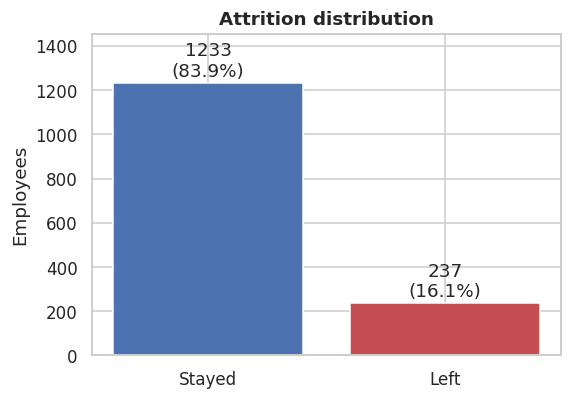

Imbalance ratio (stayed : left) = 5.2 : 1


In [72]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(5.5, 3.8))
bars = ax.bar([LABELS[i] for i in counts.index], counts.values, color=[PALETTE[i] for i in counts.index])
for b, c, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, c + 10, f"{c}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18); ax.set_title("Attrition distribution"); ax.set_ylabel("Employees")
plt.show()
print(f"Imbalance ratio (stayed : left) = {counts[0] / counts[1]:.1f} : 1")

### 3.2 Numeric features by attrition

Density of each continuous variable for leavers (red) and stayers (blue). Each class is normalised separately so the 5:1 imbalance does not hide the shape.

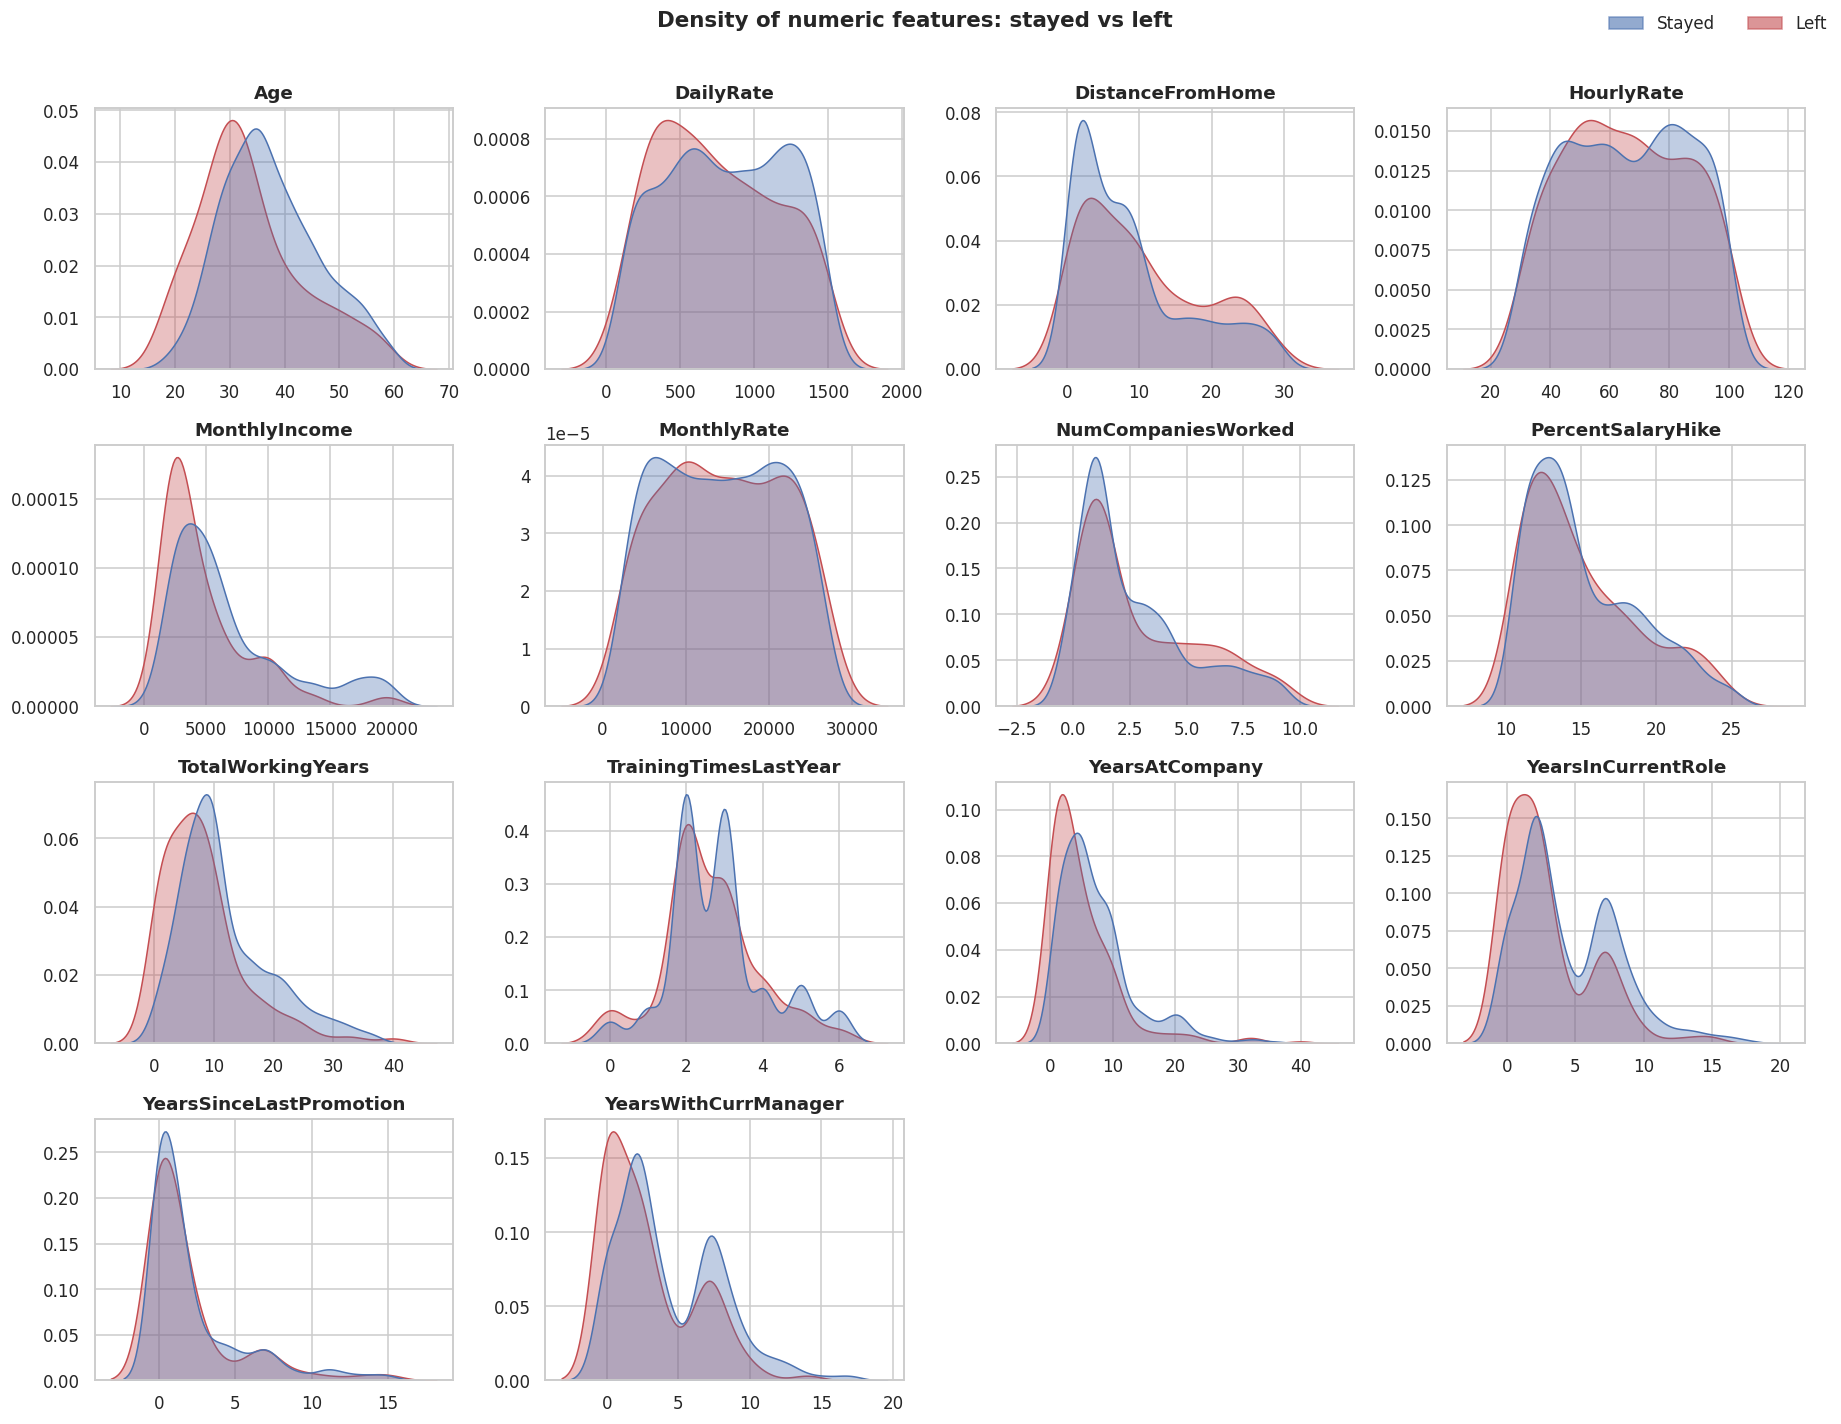

In [73]:
fig, axes = grid_axes(len(NUM_COLS), ncols=4, w=4.2, h=3.2)
for ax, col in zip(axes, NUM_COLS):
    sns.kdeplot(data=df, x=col, hue=TARGET, palette=PALETTE, common_norm=False, fill=True, alpha=.35,
                legend=False, ax=ax, warn_singular=False)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE[k], alpha=.6) for k in (0, 1)],
           labels=["Stayed", "Left"], loc="upper right", ncol=2, frameon=False)
fig.suptitle("Density of numeric features: stayed vs left", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Box plots**: medians, spread and outliers that a density curve smooths away

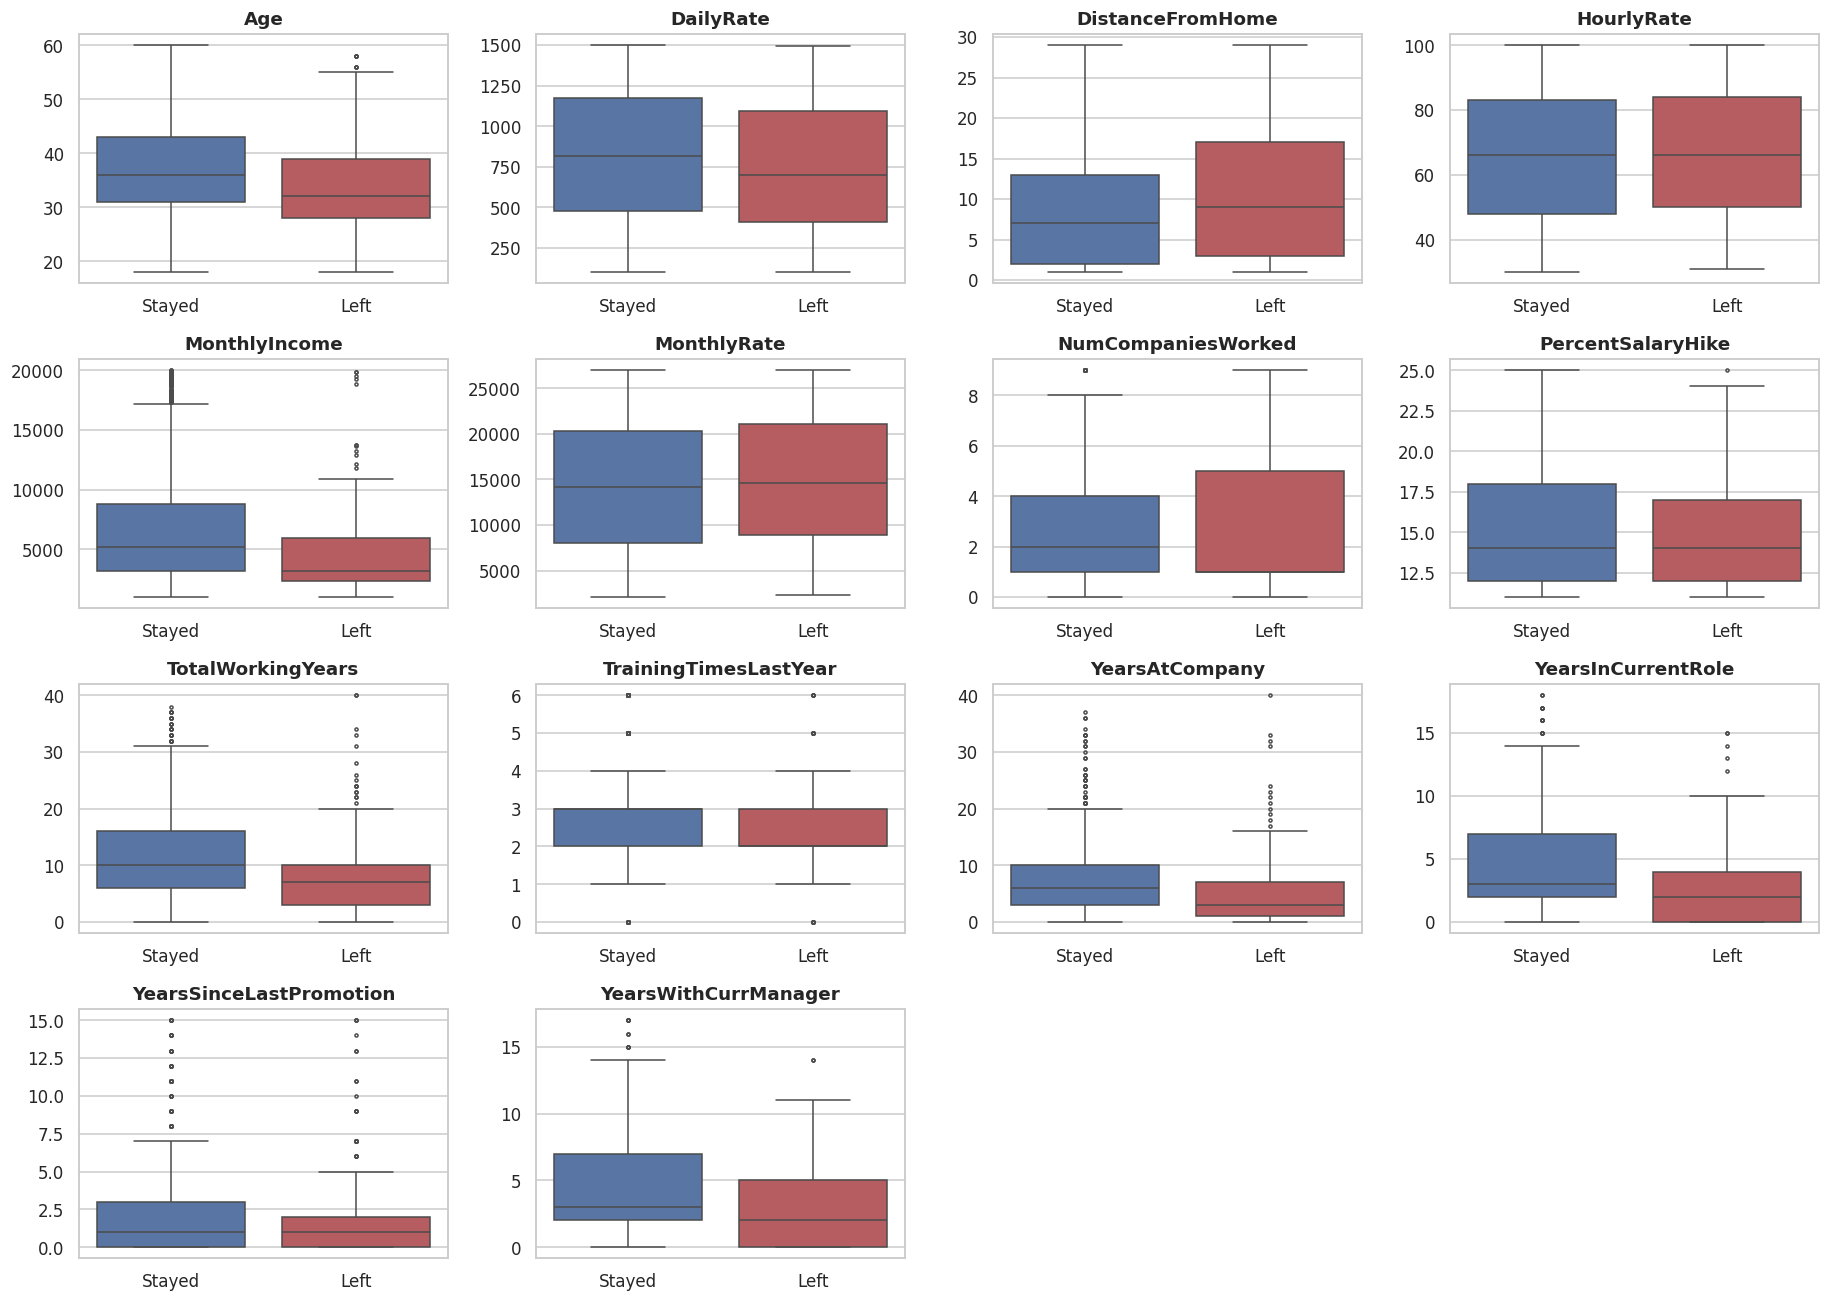

In [74]:
fig, axes = grid_axes(len(NUM_COLS), ncols=4, w=4.2, h=3.0)
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, palette=PALETTE, hue=TARGET, legend=False, fliersize=2, linewidth=1, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed", "Left"]); ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 3.3 Statistical tests for numeric and ordinal features

Mann-Whitney U test: comparing leavers vs stayers for every numeric/ordinal variable. The effect size is the rank-biserial correlation `r` (negative = leavers have lower values). A Bonferroni threshold corrects for running ~23 tests at once.


In [75]:
rows = []
for col in NUM_COLS + ORDINAL_COLS:
    a = df.loc[df[TARGET] == 1, col]; b = df.loc[df[TARGET] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": col, "median_left": a.median(), "median_stayed": b.median(),
                 "mean_left": a.mean(), "mean_stayed": b.mean(),
                 "effect_size_r": 2 * u / (len(a) * len(b)) - 1, "p_value": p})
mw = pd.DataFrame(rows).set_index("feature")
alpha_bonf = 0.05 / len(mw)
mw["significant (Bonferroni)"] = mw["p_value"] < alpha_bonf
mw = mw.reindex(mw["effect_size_r"].abs().sort_values(ascending=False).index)
print(f"Bonferroni threshold: p < {alpha_bonf:.4f}")
mw.style.format({"p_value": "{:.2e}"}).background_gradient(subset=["effect_size_r"], cmap="RdBu_r", vmin=-.4, vmax=.4)

Bonferroni threshold: p < 0.0022


,median_left,median_stayed,mean_left,mean_stayed,effect_size_r,p_value,significant (Bonferroni)
feature,,,,,,,
TotalWorkingYears,7.000000,10.000000,8.244726,11.862936,-0.311706,2.40e-14,True
MonthlyIncome,3202.000000,5204.000000,4787.092827,6832.739659,-0.311340,2.95e-14,True
YearsAtCompany,3.000000,6.000000,5.130802,7.369019,-0.297915,2.92e-13,True
JobLevel,1.000000,2.000000,1.637131,2.145985,-0.283217,2.96e-13,True
YearsInCurrentRole,2.000000,3.000000,2.902954,4.484185,-0.279901,4.43e-12,True
YearsWithCurrManager,2.000000,3.000000,2.852321,4.367397,-0.272048,1.81e-11,True
Age,32.000000,36.000000,33.607595,37.561233,-0.268643,5.30e-11,True
StockOptionLevel,0.000000,1.000000,0.527426,0.845093,-0.249808,4.01e-11,True
JobInvolvement,3.000000,3.000000,2.518987,2.770479,-0.165310,4.65e-06,True


### 3.4 Categorical features

the attrition rate (bar) and group size (n), dashed line is the company average.

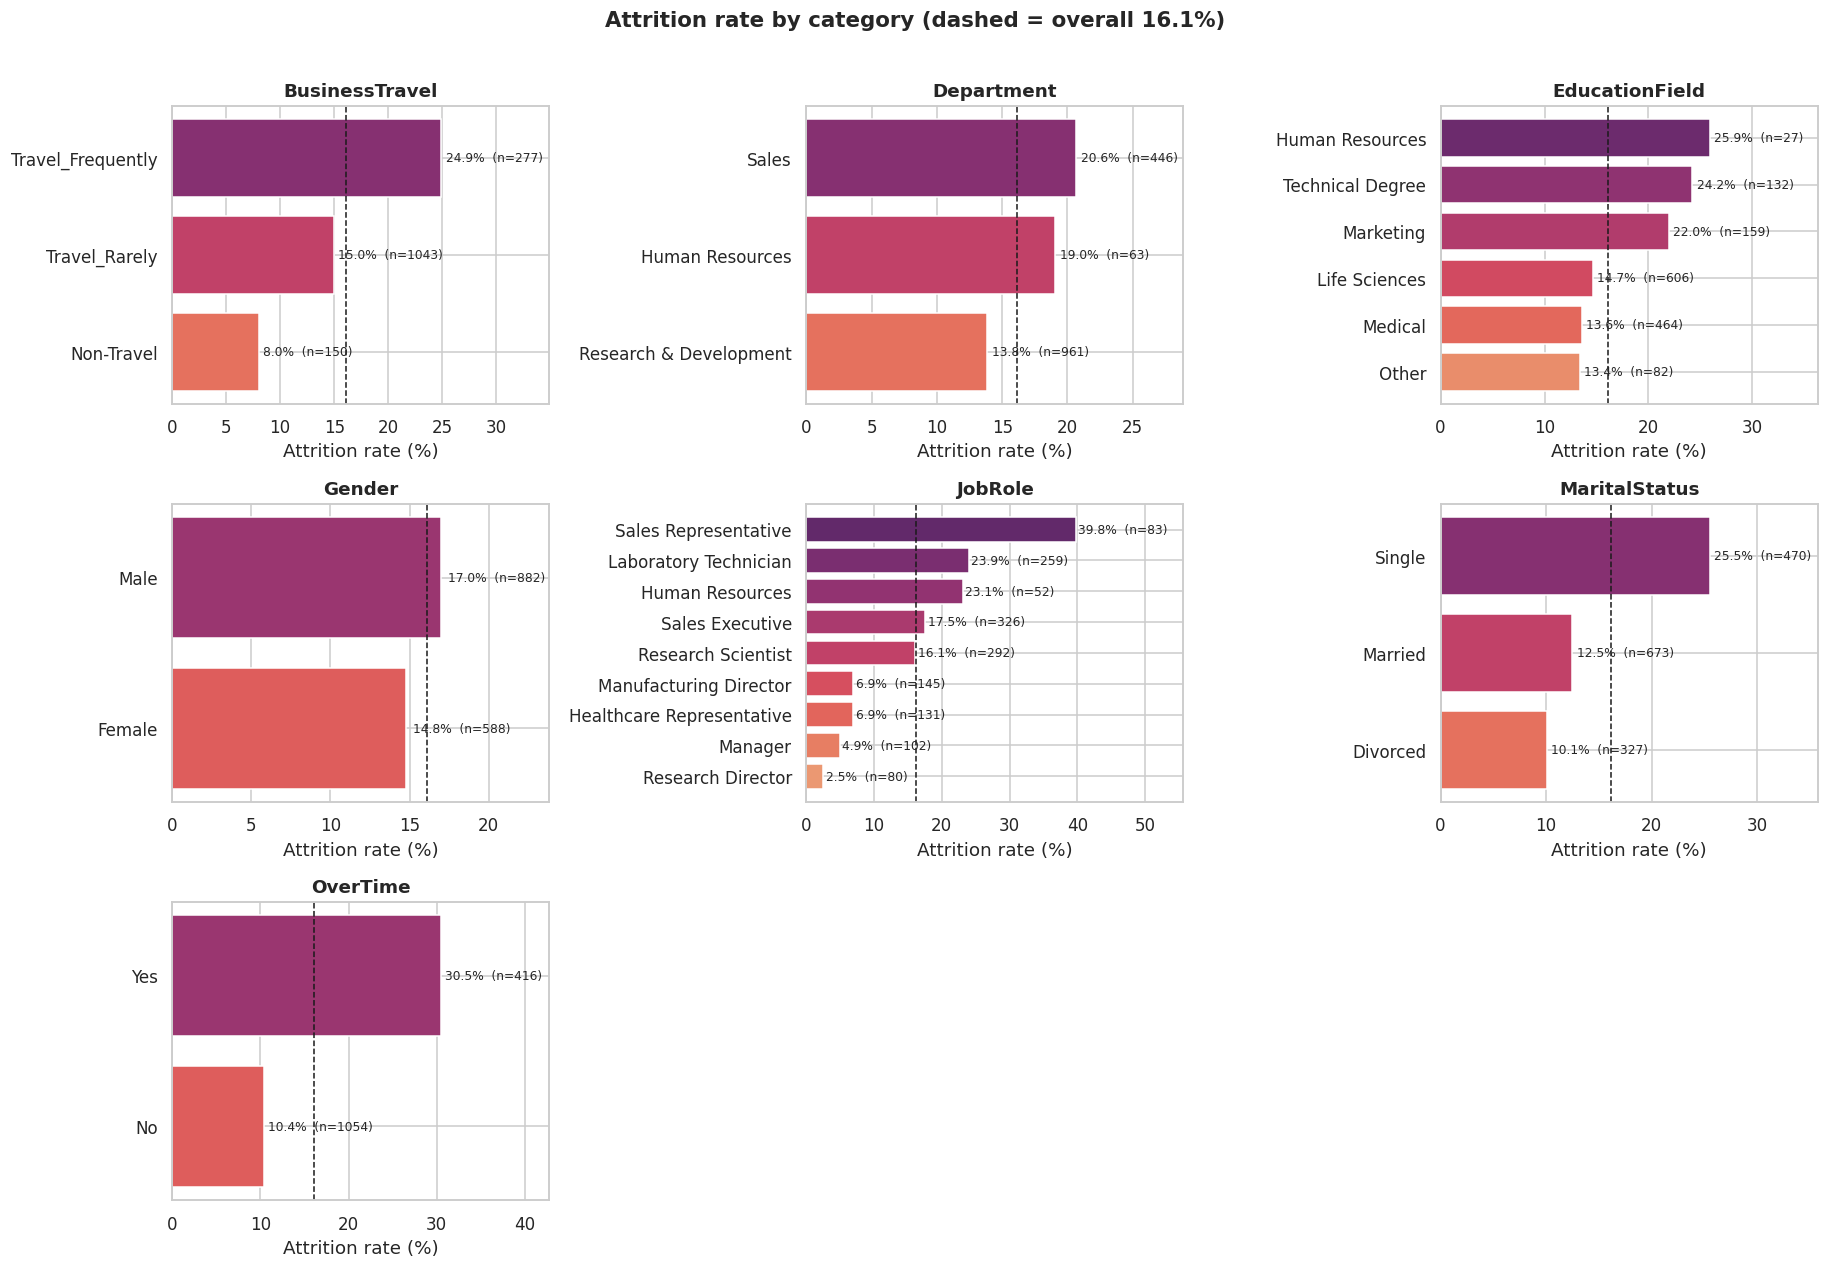

In [76]:
overall = df[TARGET].mean()
fig, axes = grid_axes(len(CAT_COLS), ncols=3, w=5.6, h=3.8)
for ax, col in zip(axes, CAT_COLS):
    g = df.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean", ascending=True)
    ax.barh(g.index.astype(str), g["mean"] * 100, color=sns.color_palette("flare", len(g)))
    ax.axvline(overall * 100, color="k", ls="--", lw=1)
    for y_, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + .4, y_, f"{m*100:.1f}%  (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, g["mean"].max() * 100 * 1.4); ax.set_title(col); ax.set_xlabel("Attrition rate (%)"); ax.set_ylabel("")
fig.suptitle(f"Attrition rate by category (dashed = overall {overall*100:.1f}%)", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Result.** Big gaps: **OverTime = Yes ≈30.5% vs No ≈10.4%**; **Sales Representative ≈40%** (vs ≈5–7% for Research Directors/Manufacturing Directors); **MaritalStatus = Single ≈25.5%** vs ≈10% for Married/Divorced; **Travel_Frequently ≈25%** vs ≈8% for Non-Travel; Sales department > R&D. `Gender` and `EducationField` differences are small.

### 3.5 Ordinal (rating-scale) features

Attrition rate at each level of the 1–4 (or 1–5) rating scales. Annotated with group size because small groups give unstable rates.

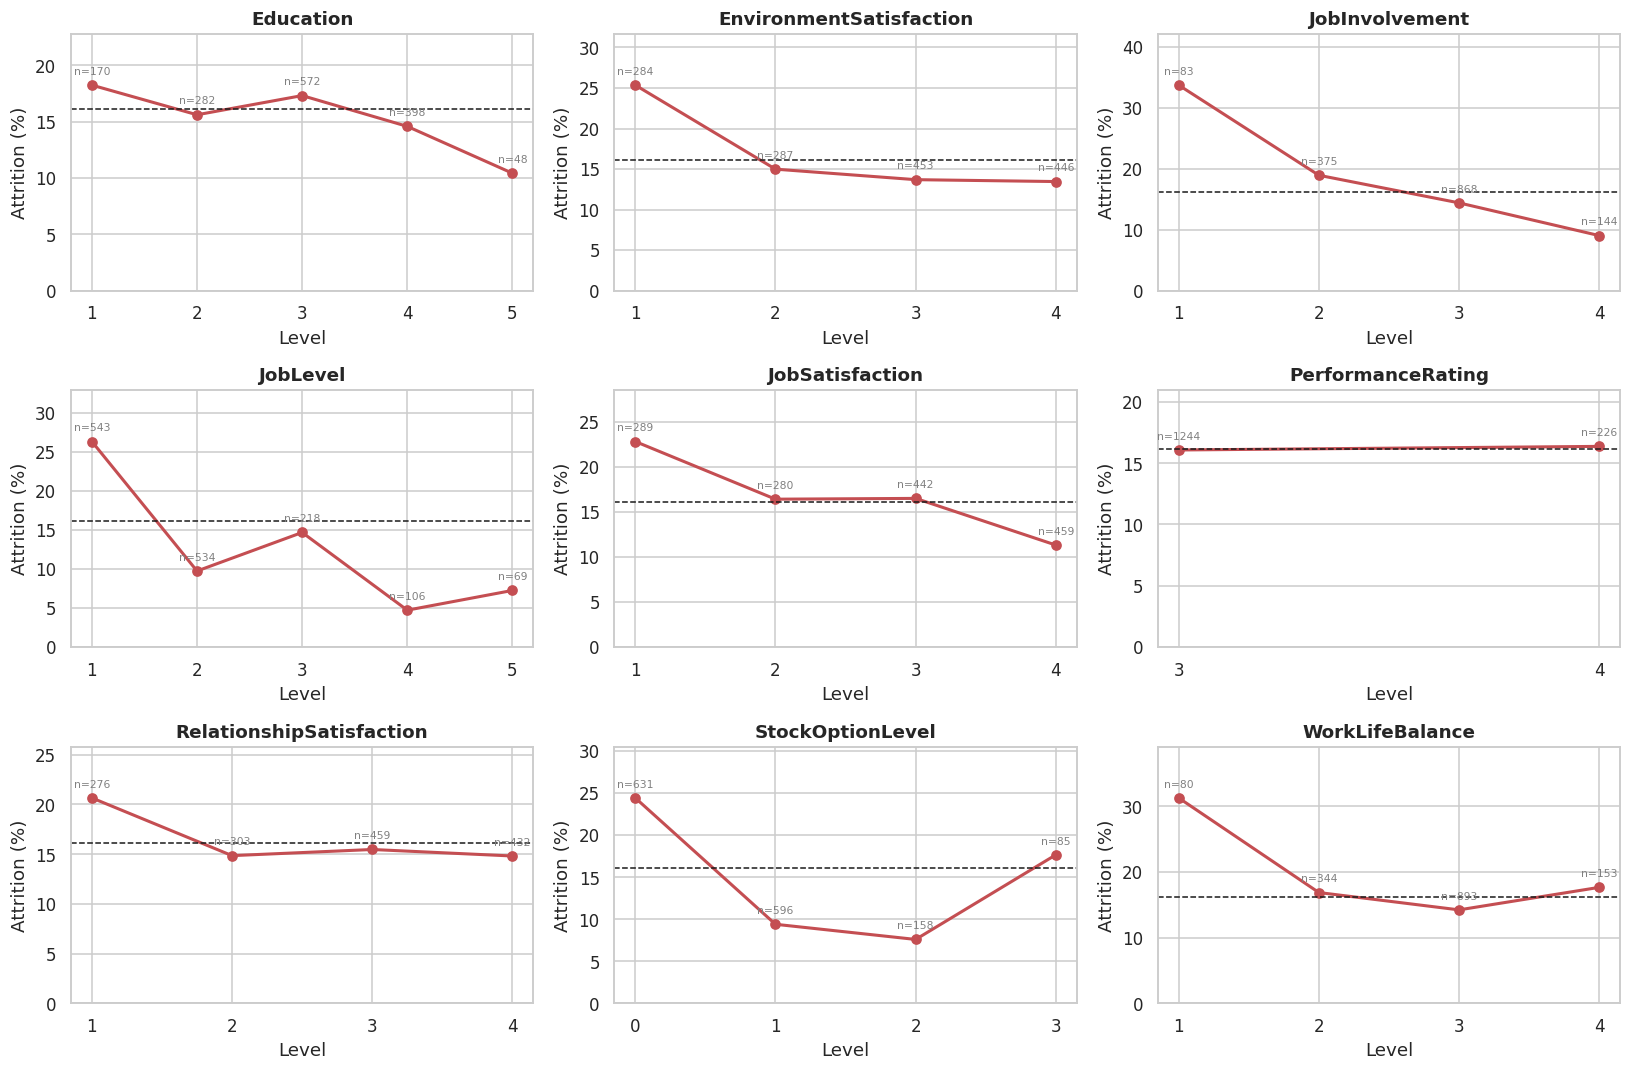

In [77]:
fig, axes = grid_axes(len(ORDINAL_COLS), ncols=3, w=5, h=3.3)
for ax, col in zip(axes, ORDINAL_COLS):
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.plot(g.index, g["mean"] * 100, marker="o", color=PALETTE[1], lw=2)
    for x_, m, n in zip(g.index, g["mean"], g["size"]):
        ax.annotate(f"n={n}", (x_, m * 100), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7, color="gray")
    ax.axhline(overall * 100, color="k", ls="--", lw=1)
    ax.set_xticks(g.index); ax.set_title(col); ax.set_ylabel("Attrition (%)"); ax.set_xlabel("Level")
    ax.set_ylim(0, max(g["mean"].max() * 100 * 1.25, overall * 130))
plt.tight_layout(); plt.show()

χ² test of independence and **Cramér's V** (0 = unrelated, 1 = perfectly related) for every categorical/ordinal feature. Red bars are significant at p < 0.05.

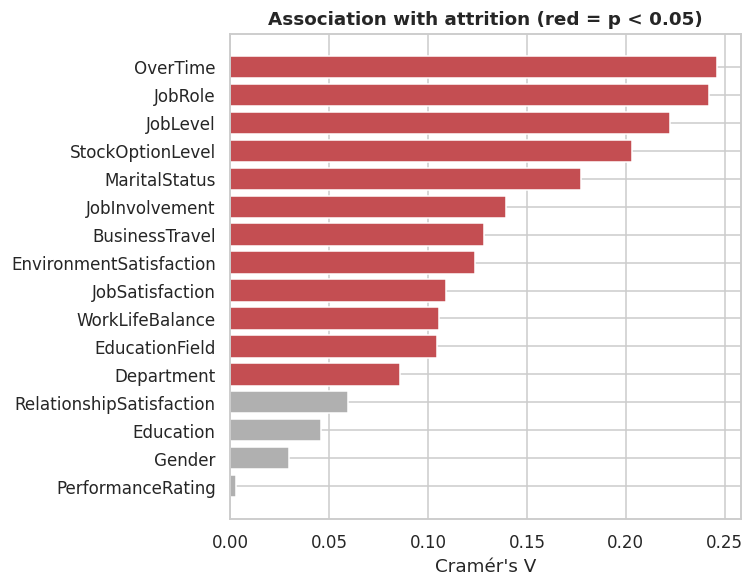

,chi2,dof,p_value,cramers_V
feature,,,,
OverTime,87.564294,1,8.16e-21,0.246118
JobRole,86.190254,8,2.75e-15,0.242142
JobLevel,72.529013,4,6.63e-15,0.222125
StockOptionLevel,60.598301,3,4.38e-13,0.203035
MaritalStatus,46.163677,2,9.46e-11,0.177211
JobInvolvement,28.492021,3,2.86e-06,0.139220
BusinessTravel,24.182414,2,5.61e-06,0.128260
EnvironmentSatisfaction,22.503881,3,5.12e-05,0.123729
JobSatisfaction,17.505077,3,5.56e-04,0.109125


In [78]:
def cramers_v(table):
    chi2_ = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2_ / (table.values.sum() * (min(table.shape) - 1)))

rows = []
for col in CAT_COLS + ORDINAL_COLS:
    table = pd.crosstab(df[col], df[TARGET])
    chi2_, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"feature": col, "chi2": chi2_, "dof": dof, "p_value": p, "cramers_V": cramers_v(table)})
chi = pd.DataFrame(rows).set_index("feature").sort_values("cramers_V", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(chi.index[::-1], chi["cramers_V"][::-1], color=["#C44E52" if p < 0.05 else "#B0B0B0" for p in chi["p_value"]][::-1])
ax.set_xlabel("Cramér's V"); ax.set_title("Association with attrition (red = p < 0.05)")
plt.tight_layout(); plt.show()
chi.style.format({"p_value": "{:.2e}"})

### 3.6 Correlations and multicollinearity

Spearman correlation matrix (rank-based: robust to skew and valid for ordinal scales) including the target.

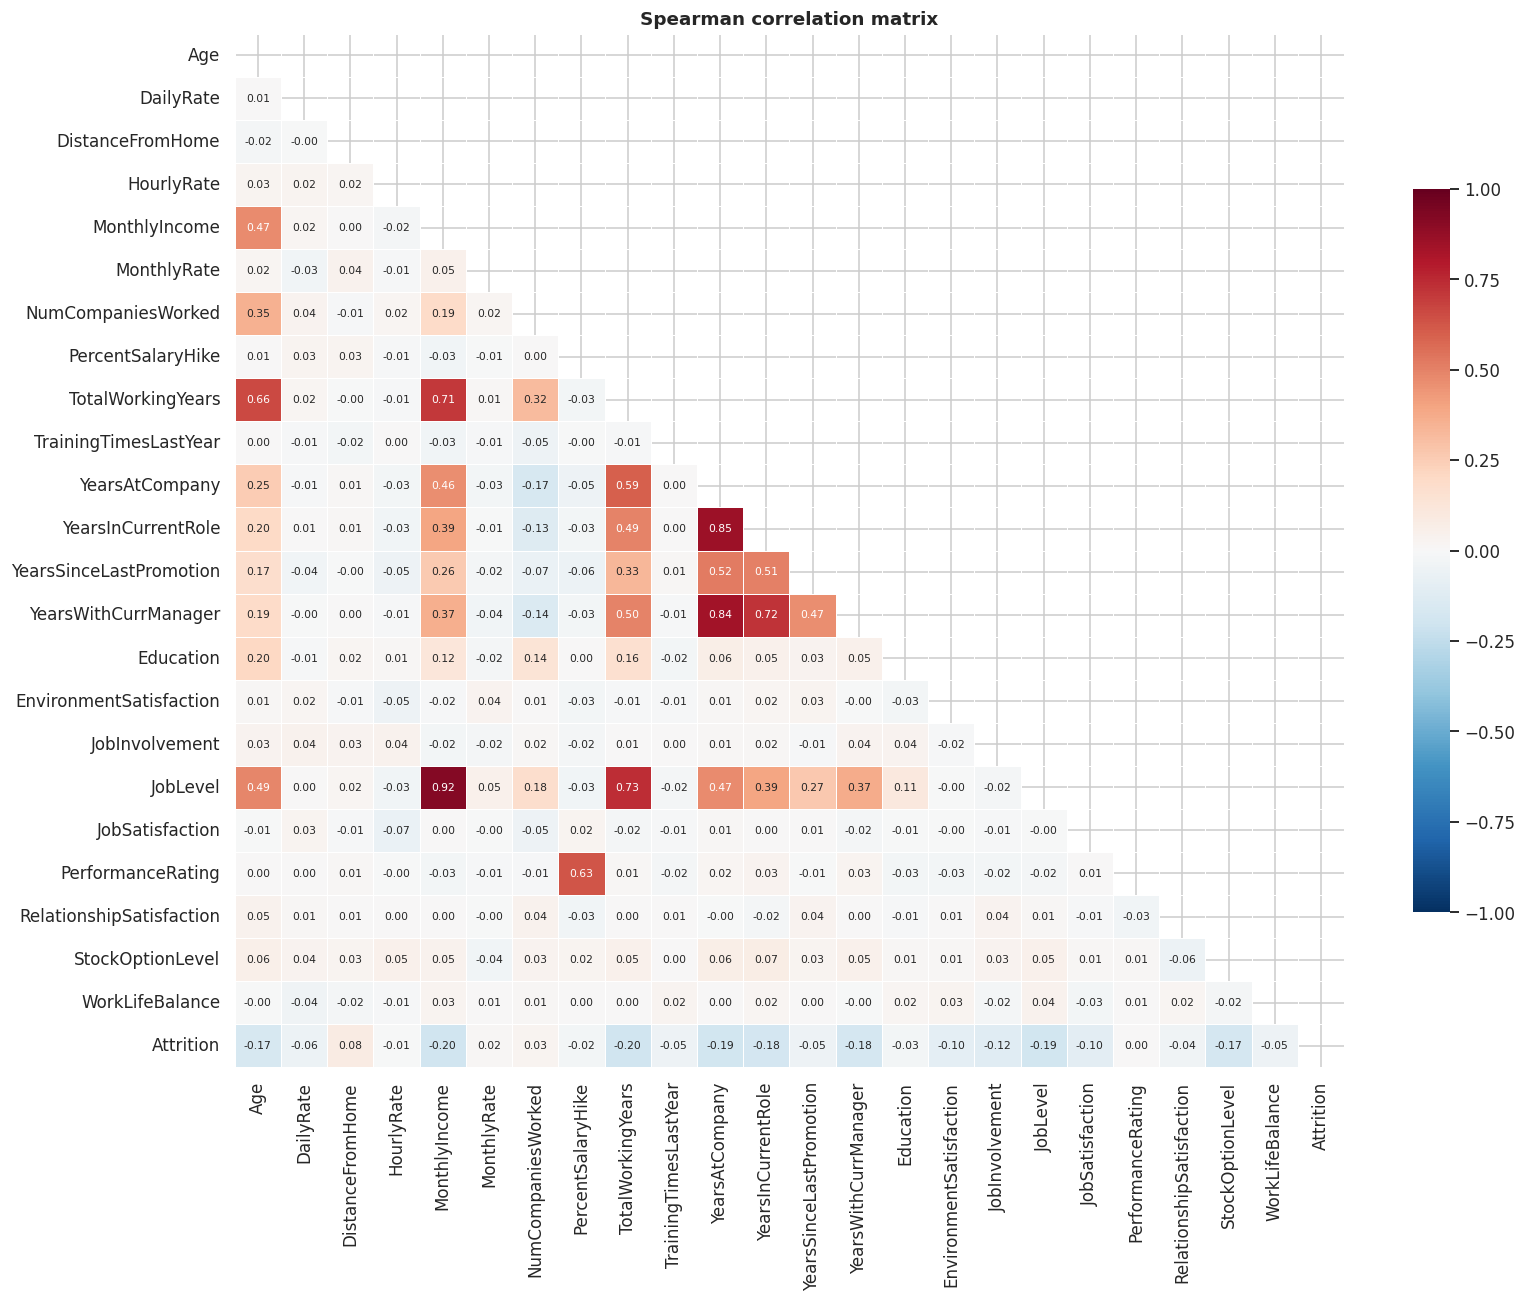

In [79]:
corr_cols = NUM_COLS + ORDINAL_COLS + [TARGET]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation matrix"); plt.tight_layout(); plt.show()

Ranks every variable by correlation with the target; (2) lists feature pairs with |ρ| > 0.7 (redundant information).

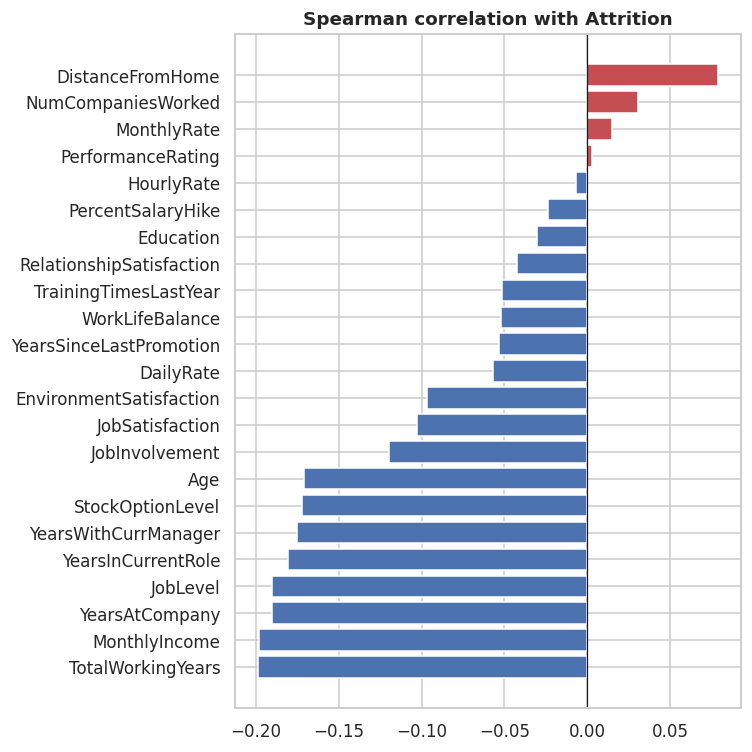

Strongly correlated pairs (|rho| > 0.7):


,,spearman
JobLevel,MonthlyIncome,0.920
YearsInCurrentRole,YearsAtCompany,0.854
YearsWithCurrManager,YearsAtCompany,0.843
JobLevel,TotalWorkingYears,0.735
YearsWithCurrManager,YearsInCurrentRole,0.725
TotalWorkingYears,MonthlyIncome,0.710


In [80]:
fig, ax = plt.subplots(figsize=(7, 7))
t = corr[TARGET].drop(TARGET).sort_values()
ax.barh(t.index, t.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in t.values])
ax.axvline(0, color="k", lw=.8); ax.set_title("Spearman correlation with Attrition")
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack()
pairs = pairs[(pairs.abs() > 0.7) & (pairs.index.get_level_values(0) != TARGET)]
pairs = pairs.sort_values(key=abs, ascending=False).rename("spearman")
print("Strongly correlated pairs (|rho| > 0.7):")
pairs.to_frame()

**Variance Inflation Factor (VIF)** : how well each feature can be reconstructed from all the others. VIF > 5 means the coefficient of that feature in a linear model is unstable.

In [81]:
def vif_table(frame):
    Z = (frame - frame.mean()) / frame.std(ddof=0)
    out = {}
    for c in Z.columns:
        y_, X_ = Z[c].values, Z.drop(columns=c).values
        beta, *_ = np.linalg.lstsq(X_, y_, rcond=None)
        r2 = 1 - (y_ - X_ @ beta).var() / y_.var()
        out[c] = 1 / max(1 - r2, 1e-9)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

vif = vif_table(df[NUM_COLS + ORDINAL_COLS].astype(float))
print("Features with VIF > 5:", list(vif[vif > 5].index))
vif.to_frame()

Features with VIF > 5: ['JobLevel', 'MonthlyIncome']


,VIF
JobLevel,11.205
MonthlyIncome,10.800
TotalWorkingYears,4.768
YearsAtCompany,4.587
YearsWithCurrManager,2.775
YearsInCurrentRole,2.719
PercentSalaryHike,2.516
PerformanceRating,2.514
Age,2.045
YearsSinceLastPromotion,1.674


### 3.7 Multivariate views (interactions)

(a) Heat-map of attrition % by Job Role × OverTime; (b) scatter of income vs age coloured by outcome.

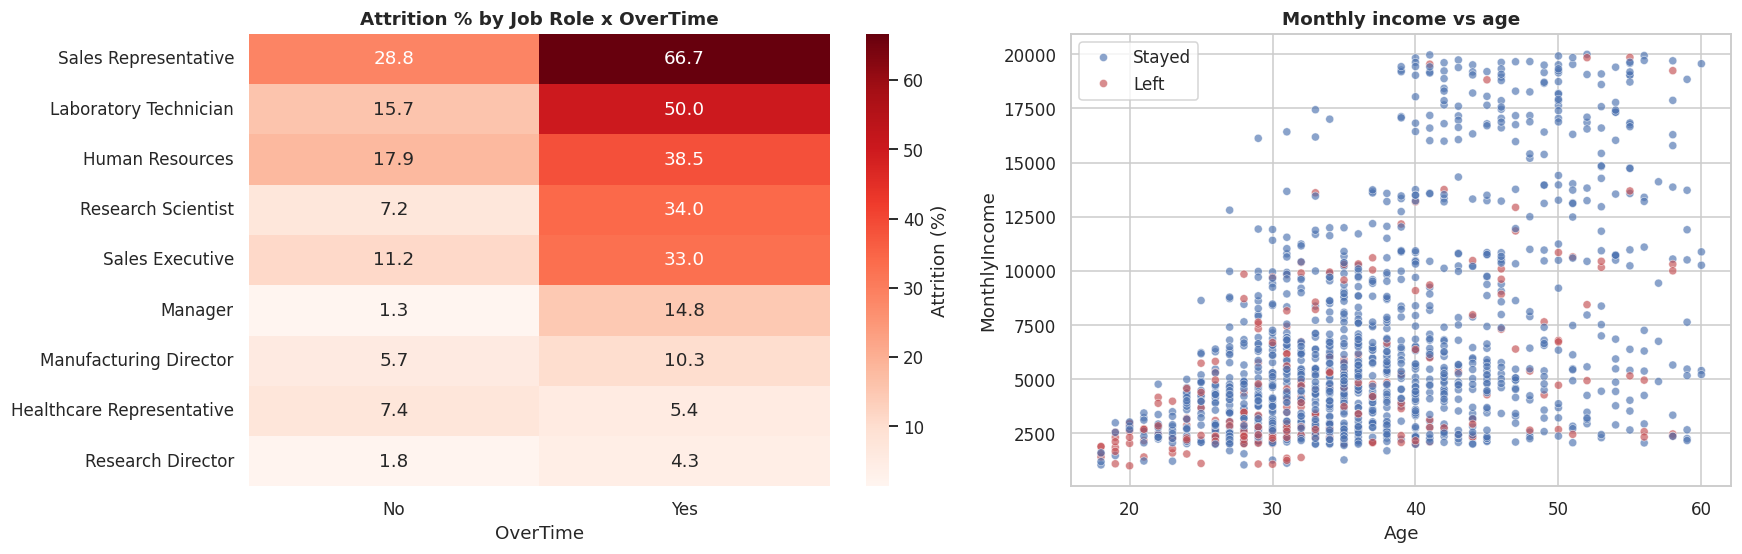

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
pt = df.pivot_table(index="JobRole", columns="OverTime", values=TARGET, aggfunc="mean") * 100
pt = pt.sort_values("Yes", ascending=False)
sns.heatmap(pt, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Attrition (%)"}, ax=axes[0])
axes[0].set_title("Attrition % by Job Role x OverTime"); axes[0].set_ylabel("")
sns.scatterplot(data=df.sample(frac=1, random_state=SEED), x="Age", y="MonthlyIncome", hue=TARGET,
                palette=PALETTE, alpha=.65, s=28, ax=axes[1])
axes[1].set_title("Monthly income vs age")
h, _ = axes[1].get_legend_handles_labels(); axes[1].legend(h, ["Stayed", "Left"], title="")
plt.tight_layout(); plt.show()

Attrition rate by age band, tenure band and income quartile.

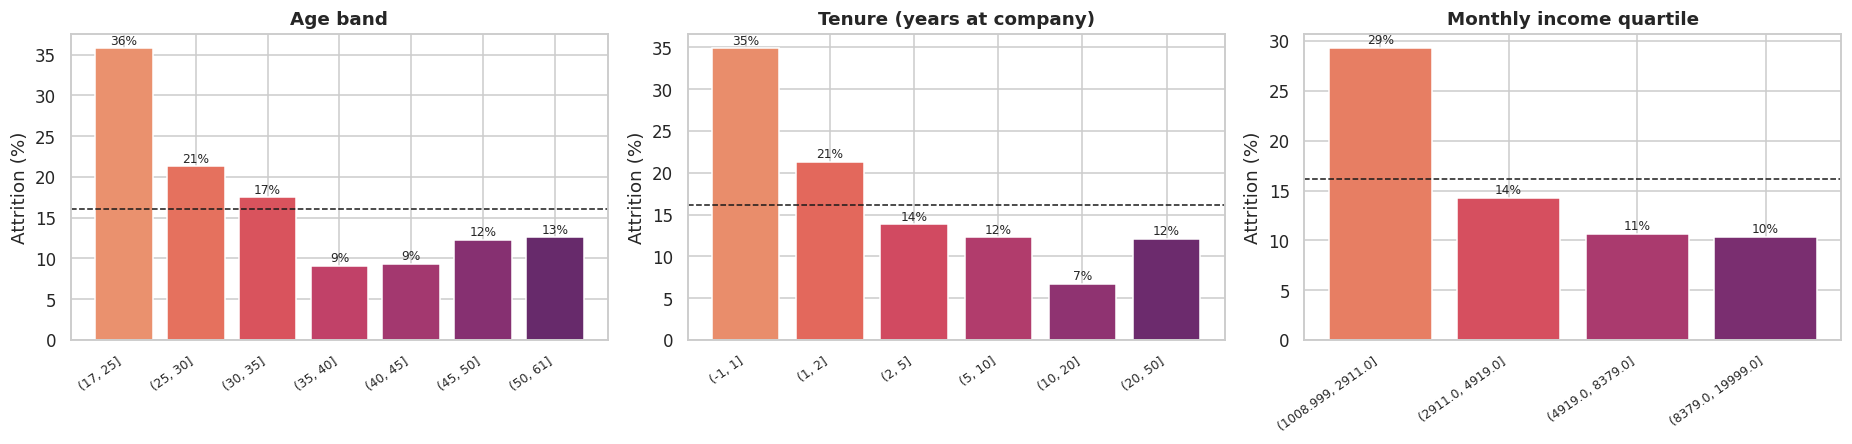

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
specs = [("Age band", pd.cut(df["Age"], [17, 25, 30, 35, 40, 45, 50, 61])),
         ("Tenure (years at company)", pd.cut(df["YearsAtCompany"], [-1, 1, 2, 5, 10, 20, 50])),
         ("Monthly income quartile", pd.qcut(df["MonthlyIncome"], 4))]
for ax, (title, bins) in zip(axes, specs):
    g = df.groupby(bins, observed=True)[TARGET].agg(["mean", "size"])
    ax.bar(range(len(g)), g["mean"] * 100, color=sns.color_palette("flare", len(g)))
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=35, ha="right", fontsize=8)
    for i, m in enumerate(g["mean"]):
        ax.text(i, m * 100 + .5, f"{m*100:.0f}%", ha="center", fontsize=8)
    ax.axhline(overall * 100, color="k", ls="--", lw=1); ax.set_title(title); ax.set_ylabel("Attrition (%)")
plt.tight_layout(); plt.show()

Tests whether risk factors **combine non-additively**: attrition for every OverTime × MaritalStatus × BusinessTravel combination with at least 20 employees.

In [84]:
combo = (df.groupby(["OverTime", "MaritalStatus", "BusinessTravel"])[TARGET]
           .agg(rate="mean", n="size").query("n >= 20").sort_values("rate", ascending=False))
combo["rate"] = combo["rate"] * 100
print("Highest-risk segments (n >= 20), attrition %:")
combo.head(8)

Highest-risk segments (n >= 20), attrition %:


rate    n
OverTime MaritalStatus BusinessTravel               
Yes      Single        Travel_Frequently 55.882   34
                       Travel_Rarely     47.674   86
         Married       Travel_Frequently 30.303   33
No       Single        Travel_Frequently 29.032   62
Yes      Married       Travel_Rarely     21.986  141
         Divorced      Travel_Rarely     17.647   68
No       Single        Travel_Rarely     14.108  241
         Divorced      Travel_Frequently 13.636   44

In [85]:
def rate(mask):
    return df.loc[mask, TARGET].mean() * 100

inc_q = pd.qcut(df["MonthlyIncome"], 4, labels=False)
role_rates = (df.groupby("JobRole")[TARGET].mean() * 100).sort_values(ascending=False)
print(f"OverTime        : {rate(df.OverTime=='Yes'):.1f}% leave with overtime vs {rate(df.OverTime=='No'):.1f}% without")
print(f"Marital status  : {rate(df.MaritalStatus=='Single'):.1f}% of singles leave vs {rate(df.MaritalStatus!='Single'):.1f}% of others")
print(f"Stock options   : {rate(df.StockOptionLevel==0):.1f}% leave with level 0 vs {rate(df.StockOptionLevel>0):.1f}% with level >= 1")
print(f"Business travel : {rate(df.BusinessTravel=='Travel_Frequently'):.1f}% leave when travelling frequently vs {rate(df.BusinessTravel!='Travel_Frequently'):.1f}% otherwise")
print(f"Job role        : highest = {role_rates.index[0]} ({role_rates.iloc[0]:.1f}%), lowest = {role_rates.index[-1]} ({role_rates.iloc[-1]:.1f}%)")
print(f"Income          : {rate(inc_q==0):.1f}% leave in the lowest income quartile vs {rate(inc_q==3):.1f}% in the highest")
print(f"Age             : {rate(df.Age<30):.1f}% leave under 30 vs {rate(df.Age>=30):.1f}% at 30+")

OverTime        : 30.5% leave with overtime vs 10.4% without
Marital status  : 25.5% of singles leave vs 11.7% of others
Stock options   : 24.4% leave with level 0 vs 9.9% with level >= 1
Business travel : 24.9% leave when travelling frequently vs 14.1% otherwise
Job role        : highest = Sales Representative (39.8%), lowest = Research Director (2.5%)
Income          : 29.3% leave in the lowest income quartile vs 10.3% in the highest
Age             : 27.9% leave under 30 vs 12.8% at 30+


## 4. Preprocessing as ONE pipeline

In [86]:
X = df.drop(columns=TARGET)
y = df[TARGET]
print(f"Raw predictors: {X.shape[1]} columns, {X.shape[0]} rows")


Raw predictors: 30 columns, 1470 rows


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def select_cat(d):
    return [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]

def select_num(d):
    return [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c])]

def build_pipeline(clf, scale=False):
    """raw employees -> one-hot (+ optional scaling) -> classifier"""
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), select_cat),
        ("num", StandardScaler() if scale else "passthrough", select_num),
    ])
    return Pipeline([
        ("prep", prep),
        ("clf", clf),
    ])


In [88]:
def feat_names(pipe):
    """Readable names of the columns the classifier actually receives."""
    return [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]

## 5. Train / test split and cross-validation scheme

In [89]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape} | attrition rate = {y_train.mean():.3%}")
print(f"Test : {X_test.shape}  | attrition rate = {y_test.mean():.3%}  ({int(y_test.sum())} leavers)")

tune_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=CFG["tune_repeats"], random_state=SEED)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"\nscale_pos_weight (neg/pos) = {pos_weight:.2f}")

Train: (1176, 30) | attrition rate = 16.156%
Test : (294, 30)  | attrition rate = 15.986%  (47 leavers)

scale_pos_weight (neg/pos) = 5.19


## 6. Models and hyper-parameter search

Five models are tuned with the **same** CV scheme, each by `GridSearchCV` or `RandomizedSearchCV` depending on `SEARCH_MODE` (Section 0):

| # | Model | Why it is here |
|---|---|---|
| 1 | Logistic Regression (elastic-net) | strong, interpretable baseline; EDA suggests mostly additive effects |
| 2 | Decision Tree | maximum readability (rules) |
| 3 | K-Nearest Neighbours | non-parametric benchmark ("similar employees behave alike") |
| 4 | Random Forest | bagging ensemble |
| 5 | XGBoost | boosting ensemble (shallow trees + strong regularisation) |

An automatic edge-check warns when the best value is still at the border of its range.

In [90]:
searches, spaces = {}, {}

def make_search(estimator, grid_space, random_space=None, n_iter=30):
    """Return the search object chosen by SEARCH_MODE. Same CV scheme and scoring for every model.
       grid   -> GridSearchCV over grid_space (every combination)
       random -> RandomizedSearchCV over random_space (or over grid_space if none is given), n_iter draws"""
    if SEARCH_MODE == "grid":
        return GridSearchCV(estimator, grid_space, scoring="roc_auc", cv=tune_cv, n_jobs=-1)
    if SEARCH_MODE != "random":
        raise ValueError("SEARCH_MODE must be 'grid' or 'random'")
    space = grid_space if random_space is None else random_space
    if all(isinstance(v, (list, tuple)) for v in space.values()):      # finite space: cannot draw more than its size
        n_iter = min(n_iter, len(ParameterGrid(space)))
    return RandomizedSearchCV(estimator, space, n_iter=n_iter, scoring="roc_auc", cv=tune_cv,
                              n_jobs=-1, random_state=SEED)

def run_search(name, search, space=None):
    search.fit(X_train, y_train)
    if space is None:
        space = getattr(search, "param_grid", None) or getattr(search, "param_distributions", {})
    searches[name], spaces[name] = search, space
    kind = "GridSearchCV" if isinstance(search, GridSearchCV) else "RandomizedSearchCV"
    n_cand = len(search.cv_results_["params"])
    print(f"{name}  [{kind}, {n_cand} candidates x {tune_cv.get_n_splits()} folds]\n  best CV ROC-AUC : {search.best_score_:.4f}")
    print(f"  best params     : {search.best_params_}")
    check_edges(name, search.best_params_, space)
    print()

def check_edges(name, best, space):
    for p, vals in space.items():
        if isinstance(vals, (list, tuple, np.ndarray)) and len(vals) > 2 and p in best:
            if any((v is None) or isinstance(v, (str, bool)) for v in vals):
                continue
            b, lo, hi = best[p], min(vals), max(vals)
            if np.isclose(b, lo) or np.isclose(b, hi):
                print(f"  [edge] {p}={b} is at the {'lower' if np.isclose(b, lo) else 'upper'} end of its range "
                      f"{[round(float(v), 4) for v in (lo, hi)]}: consider extending it (or accept: simpler is fine).")


### 6.1 Logistic Regression (elastic-net)

Pipeline =one-hot + **StandardScaler** (needed for a penalised linear model) → Logistic Regression with class weights. Grid over the regularisation strength `C` and the L1/L2 mix `l1_ratio` (0 = ridge, 1 = lasso).



In [91]:
lr_space = {
    "clf__C": list(np.logspace(-3, 0.5,8)),
    "clf__l1_ratio":[0.0, 0.25, 0.5, 0.75, 1.0],
}
lr_base = LogisticRegression(penalty="elasticnet", solver="saga", class_weight="balanced",
                             max_iter=3000, tol=1e-3, random_state=SEED)
run_search("Logistic Regression",
           make_search(build_pipeline(lr_base, scale=True), lr_space, n_iter=CFG["n_iter_lr"]))

Logistic Regression  [GridSearchCV, 40 candidates x 10 folds]
  best CV ROC-AUC : 0.8308
  best params     : {'clf__C': np.float64(0.1), 'clf__l1_ratio': 0.0}
  [edge] clf__l1_ratio=0.0 is at the lower end of its range [0.0, 1.0]: consider extending it (or accept: simpler is fine).



### 6.2 Decision Tree

**What this cell does.** Exhaustive grid over depth, leaf size, split criterion and cost-complexity pruning. The grid now includes **shallower and larger-leaf** trees than v2 (whose best values were on the border).

**Expected result.** Best CV ROC-AUC ≈ **0.70–0.76**, clearly the weakest: a single tree is high-variance. Expect a shallow tree (`max_depth` 2–4) with big leaves (`min_samples_leaf` ≥ 20).

In [92]:
dt_space = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [2, 3, 4, 5, 6, 8],
    "clf__min_samples_leaf":[5, 10, 20, 30, 50],
    "clf__ccp_alpha": [0.0, 0.002, 0.005, 0.01],
}
run_search("Decision Tree",
           make_search(build_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
                       dt_space, n_iter=CFG["n_iter_dt"]))

Decision Tree  [GridSearchCV, 240 candidates x 10 folds]
  best CV ROC-AUC : 0.7168
  best params     : {'clf__ccp_alpha': 0.01, 'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 10}
  [edge] clf__ccp_alpha=0.01 is at the upper end of its range [0.0, 0.01]: consider extending it (or accept: simpler is fine).



### 6.3 K-Nearest Neighbours (KNN)

In [93]:
knn_grid = {
    "clf__n_neighbors": [5, 11, 15, 21, 31, 41, 51, 75],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2],
}
knn_random = {
    "clf__n_neighbors": randint(5, 101),
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2],
}
run_search("KNN",
           make_search(build_pipeline(KNeighborsClassifier(), scale=True), knn_grid, knn_random,
                       n_iter=CFG["n_iter_knn"]))

KNN  [GridSearchCV, 32 candidates x 10 folds]
  best CV ROC-AUC : 0.8037
  best params     : {'clf__n_neighbors': 75, 'clf__p': 1, 'clf__weights': 'distance'}
  [edge] clf__n_neighbors=75 is at the upper end of its range [5.0, 75.0]: consider extending it (or accept: simpler is fine).



### 6.4 Random Forest

In [94]:
rf_grid = {
    "clf__n_estimators": [300, 500],
    "clf__max_depth": [4, 6, 8, None],
    "clf__min_samples_leaf": [2, 5, 10],
    "clf__max_features": ["sqrt", 0.3],
    "clf__class_weight": ["balanced", "balanced_subsample"],
}
rf_random = {
    "clf__n_estimators": [300, 500, 800],
    "clf__max_depth": [3, 4, 5, 6, 8, 12, None],
    "clf__min_samples_leaf": [1, 2, 3, 5, 8, 12],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__max_features": ["sqrt", "log2", 0.2, 0.35, 0.5],
    "clf__max_samples": [None, 0.6, 0.8],
    "clf__criterion": ["gini", "entropy"],
    "clf__class_weight": ["balanced", "balanced_subsample", None],
}
run_search("Random Forest",
           make_search(build_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1)),
                       rf_grid, rf_random, n_iter=CFG["n_iter_rf"]))

Random Forest  [GridSearchCV, 96 candidates x 10 folds]
  best CV ROC-AUC : 0.8025
  best params     : {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 500}
  [edge] clf__min_samples_leaf=2 is at the lower end of its range [2.0, 10.0]: consider extending it (or accept: simpler is fine).



### 6.5 XGBoost

In [95]:
xgb_grid = {
    "clf__max_depth": [1, 2, 3],
    "clf__learning_rate": [0.03, 0.1],
    "clf__n_estimators": [150, 300, 500],
    "clf__colsample_bytree": [0.5, 0.8],
    "clf__min_child_weight": [1, 5],
    "clf__reg_lambda": [1, 10],
    "clf__scale_pos_weight": [1.0, float(pos_weight)],
}
xgb_random = {
    "clf__n_estimators": randint(100, 600),
    "clf__max_depth": [1, 2, 3, 4],
    "clf__learning_rate": loguniform(0.01, 0.2),
    "clf__subsample": uniform(0.5, 0.5),
    "clf__colsample_bytree": uniform(0.3, 0.7),
    "clf__min_child_weight": randint(1, 15),
    "clf__gamma": uniform(0, 3),
    "clf__reg_lambda": loguniform(1, 50),
    "clf__reg_alpha": loguniform(1e-3, 5),
    "clf__scale_pos_weight": [1.0, float(np.sqrt(pos_weight)), pos_weight],
}
xgb_base = XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                         random_state=SEED, n_jobs=1, verbosity=0)
run_search("XGBoost",
           make_search(build_pipeline(xgb_base), xgb_grid, xgb_random, n_iter=CFG["n_iter_xgb"]))

MODEL_ORDER = ["Logistic Regression", "Decision Tree", "KNN", "Random Forest", "XGBoost"]  # simple -> complex
models = {n: searches[n].best_estimator_ for n in MODEL_ORDER}
MODEL_COLORS = {"Logistic Regression": "#4C72B0", "Decision Tree": "#8172B3",
                "KNN": "#CCB974", "Random Forest": "#55A868", "XGBoost": "#DD8452"}

XGBoost  [GridSearchCV, 288 candidates x 10 folds]
  best CV ROC-AUC : 0.8419
  best params     : {'clf__colsample_bytree': 0.5, 'clf__learning_rate': 0.1, 'clf__max_depth': 1, 'clf__min_child_weight': 5, 'clf__n_estimators': 500, 'clf__reg_lambda': 1, 'clf__scale_pos_weight': 1.0}
  [edge] clf__max_depth=1 is at the lower end of its range [1.0, 3.0]: consider extending it (or accept: simpler is fine).
  [edge] clf__n_estimators=500 is at the upper end of its range [150.0, 500.0]: consider extending it (or accept: simpler is fine).



**What this cell does.** Collects the tuned configuration of every model in one table (the 'best configuration' summary).

**Expected result.** A 5-row table: model, tuning CV ROC-AUC (all on the **same** scheme, so they are comparable now) and the chosen hyper-parameters. Remember these scores are slightly optimistic because they were used to choose the settings; unbiased comparison comes in Section 7.

In [96]:
tuned = pd.DataFrame({
    "tuning CV ROC-AUC": {n: searches[n].best_score_ for n in MODEL_ORDER},
    "best hyper-parameters": {n: {k.replace("clf__", ""): (round(v, 4) if isinstance(v, (float, np.floating)) else v)
                                  for k, v in searches[n].best_params_.items()} for n in MODEL_ORDER},
})
pd.set_option("display.max_colwidth", 200)
tuned

,tuning CV ROC-AUC,best hyper-parameters
Logistic Regression,0.831,"{'C': 0.1, 'l1_ratio': 0.0}"
Decision Tree,0.717,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}"
KNN,0.804,"{'n_neighbors': 75, 'p': 1, 'weights': 'distance'}"
Random Forest,0.802,"{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 500}"
XGBoost,0.842,"{'colsample_bytree': 0.5, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 5, 'n_estimators': 500, 'reg_lambda': 1, 'scale_pos_weight': 1.0}"


## 7. Model selection by repeated cross-validation

We run the repeated CV for every tuned model, collecting ROC-AUC and PR-AUC on validation folds and ROC-AUC on the training folds (for the overfitting check). Then applies the parsimony rule and runs a paired comparison between the selected model and the strongest alternative.

In [97]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=CFG["select_repeats"], random_state=SEED + 1)

cv_scores = {}
for n, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=rcv, n_jobs=-1, return_train_score=True,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
    cv_scores[n] = pd.DataFrame({"roc_auc": r["test_roc_auc"], "pr_auc": r["test_pr_auc"],
                                 "train_roc_auc": r["train_roc_auc"]})

cv_summary = pd.DataFrame({
    n: {"ROC-AUC mean": s["roc_auc"].mean(), "ROC-AUC std": s["roc_auc"].std(),
        "PR-AUC mean": s["pr_auc"].mean(), "PR-AUC std": s["pr_auc"].std(),
        "Train ROC-AUC (CV)": s["train_roc_auc"].mean()} for n, s in cv_scores.items()
}).T.loc[MODEL_ORDER]

top = cv_summary["ROC-AUC mean"].max()
eligible = [n for n in MODEL_ORDER if cv_summary.loc[n, "ROC-AUC mean"] >= top - TIE_TOL]
best_name = eligible[0]                                   # simplest model among the (near-)best
strongest = cv_summary["ROC-AUC mean"].idxmax()
print(f"Best mean CV ROC-AUC     : {strongest} ({top:.3f})")
print(f"Models within {TIE_TOL} of it : {eligible}")
print(f"==> SELECTED (parsimony rule): {best_name}  (CV ROC-AUC = {cv_summary.loc[best_name, 'ROC-AUC mean']:.3f})")

others = [n for n in MODEL_ORDER if n != best_name]
runner_up = max(others, key=lambda n: cv_summary.loc[n, "ROC-AUC mean"])
diff = cv_scores[best_name]["roc_auc"] - cv_scores[runner_up]["roc_auc"]
print(f"Paired difference vs strongest alternative ({runner_up}): {diff.mean():+.4f} +/- {diff.std():.4f} "
      f"| selected model wins in {(diff > 0).mean():.0%} of {len(diff)} folds")
if abs(diff.mean()) < diff.std():
    print("-> The gap is smaller than its own fold-to-fold noise: the two models are practically tied.")

cv_summary.style.format("{:.3f}").background_gradient(subset=["ROC-AUC mean", "PR-AUC mean"], cmap="Greens")

Best mean CV ROC-AUC     : XGBoost (0.836)
Models within 0.01 of it : ['Logistic Regression', 'XGBoost']
==> SELECTED (parsimony rule): Logistic Regression  (CV ROC-AUC = 0.829)
Paired difference vs strongest alternative (XGBoost): -0.0070 +/- 0.0170 | selected model wins in 36% of 25 folds
-> The gap is smaller than its own fold-to-fold noise: the two models are practically tied.


,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,Train ROC-AUC (CV)
Logistic Regression,0.829,0.039,0.627,0.066,0.876
Decision Tree,0.690,0.040,0.333,0.049,0.838
KNN,0.798,0.036,0.541,0.070,1.000
Random Forest,0.793,0.037,0.547,0.067,1.000
XGBoost,0.836,0.038,0.654,0.065,0.916


/tmp/ipykernel_48/2336677262.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=MODEL_ORDER, patch_artist=True, showmeans=True)


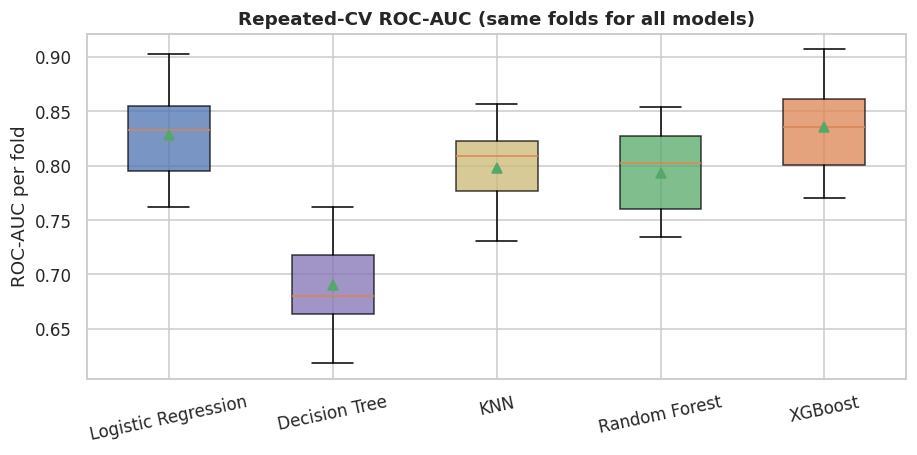

In [98]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
data = [cv_scores[n]["roc_auc"].values for n in MODEL_ORDER]
bp = ax.boxplot(data, labels=MODEL_ORDER, patch_artist=True, showmeans=True)
for patch, n in zip(bp["boxes"], MODEL_ORDER):
    patch.set_facecolor(MODEL_COLORS[n]); patch.set_alpha(.75)
ax.set(ylabel="ROC-AUC per fold", title="Repeated-CV ROC-AUC (same folds for all models)")
plt.xticks(rotation=12); plt.tight_layout(); plt.show()

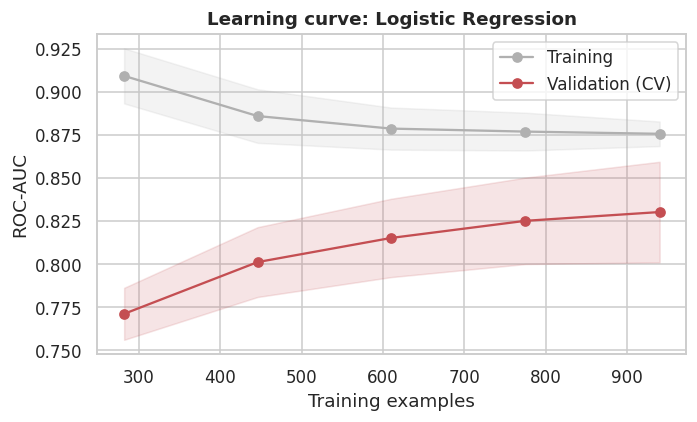

In [99]:
sizes, tr_sc, va_sc = learning_curve(clone(models[best_name]), X_train, y_train, cv=cv5, scoring="roc_auc",
                                     train_sizes=np.linspace(0.3, 1.0, 5), n_jobs=-1, random_state=SEED, shuffle=True)
fig, ax = plt.subplots(figsize=(6.5, 4))
for sc, lab, col in [(tr_sc, "Training", "#B0B0B0"), (va_sc, "Validation (CV)", "#C44E52")]:
    ax.plot(sizes, sc.mean(1), marker="o", color=col, label=lab)
    ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=.15)
ax.set(title=f"Learning curve: {best_name}", xlabel="Training examples", ylabel="ROC-AUC"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Final model: calibration, thresholds, business value

### 8.1 Calibrated final model

In [100]:
final_model = CalibratedClassifierCV(estimator=clone(models[best_name]), method="sigmoid", cv=5).fit(X_train, y_train)

p_raw   = models[best_name].predict_proba(X_test)[:, 1]
p_final = final_model.predict_proba(X_test)[:, 1]
base_brier = y_test.mean() * (1 - y_test.mean())
cal = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, p_raw), roc_auc_score(y_test, p_final)],
    "PR-AUC":  [average_precision_score(y_test, p_raw), average_precision_score(y_test, p_final)],
    "Brier":   [brier_score_loss(y_test, p_raw), brier_score_loss(y_test, p_final)],
}, index=[f"{best_name} (raw)", f"{best_name} (calibrated)"])
print(f"Brier score of 'predict the base rate for everyone' = {base_brier:.3f}")
cal.style.format("{:.3f}")

Brier score of 'predict the base rate for everyone' = 0.134


,ROC-AUC,PR-AUC,Brier
Logistic Regression (raw),0.807,0.576,0.156
Logistic Regression (calibrated),0.807,0.568,0.100


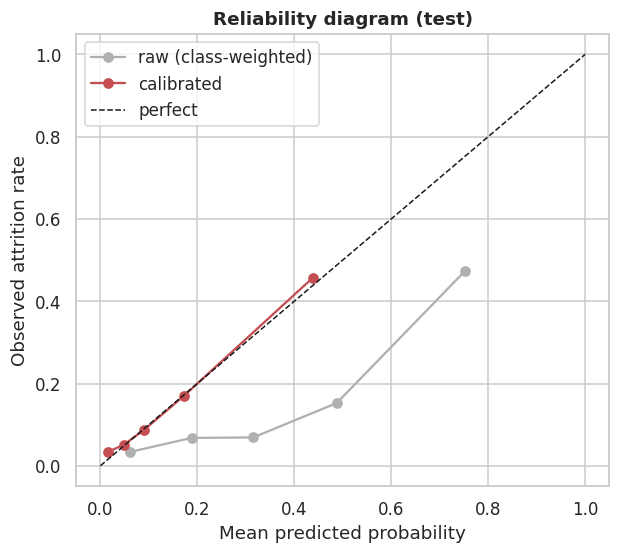

In [101]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for p, lab, col in [(p_raw, "raw (class-weighted)", "#B0B0B0"), (p_final, "calibrated", "#C44E52")]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=5, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", color=col, label=lab)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set(title="Reliability diagram (test)", xlabel="Mean predicted probability", ylabel="Observed attrition rate"); ax.legend()
plt.tight_layout(); plt.show()

### 8.2 Choosing the decision threshold

F1-optimal threshold      : 0.311
Cost-optimal threshold    : 0.250   (theory: C_INT/(SUCCESS*C_MISS) = 0.167)


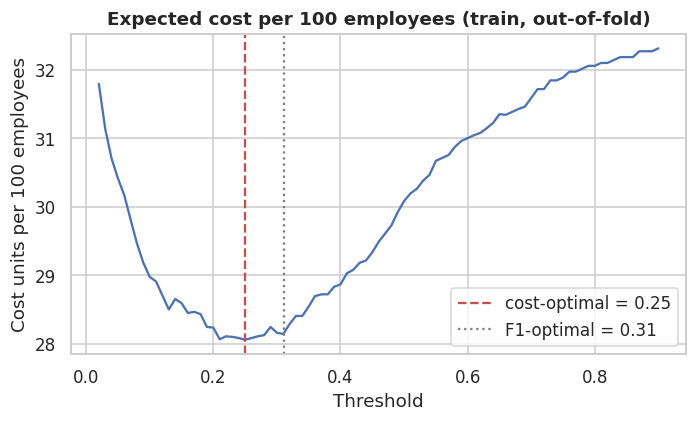

In [102]:
oof_final = cross_val_predict(clone(final_model), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])

def expected_cost(y_true, p, thr):
    y_arr = np.asarray(y_true); flag = np.asarray(p) >= thr
    tp = int((flag & (y_arr == 1)).sum()); fp = int((flag & (y_arr == 0)).sum()); fn = int((~flag & (y_arr == 1)).sum())
    return C_MISS * (fn + (1 - SUCCESS) * tp) + C_INT * (tp + fp)

grid_thr = np.linspace(0.02, 0.90, 89)
costs = np.array([expected_cost(y_train, oof_final, t) for t in grid_thr])
thr_f1   = best_f1_threshold(y_train, oof_final)
thr_cost = float(grid_thr[costs.argmin()])
print(f"F1-optimal threshold      : {thr_f1:.3f}")
print(f"Cost-optimal threshold    : {thr_cost:.3f}   (theory: C_INT/(SUCCESS*C_MISS) = {C_INT/(SUCCESS*C_MISS):.3f})")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(grid_thr, costs / len(y_train) * 100, color="#4C72B0")
ax.axvline(thr_cost, color="#C44E52", ls="--", label=f"cost-optimal = {thr_cost:.2f}")
ax.axvline(thr_f1, color="gray", ls=":", label=f"F1-optimal = {thr_f1:.2f}")
ax.set(title="Expected cost per 100 employees (train, out-of-fold)", xlabel="Threshold", ylabel="Cost units per 100 employees"); ax.legend()
plt.tight_layout(); plt.show()

In [103]:
def metrics_at(y_true, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "Flagged %": pred.mean() * 100}

baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
rows = {"Baseline: flag nobody": metrics_at(y_test, baseline.predict_proba(X_test)[:, 1], 0.5)}
for tag, thr in [("0.2", 0.2), (f"F1-optimal ({thr_f1:.2f})", thr_f1), (f"cost-optimal ({thr_cost:.2f})", thr_cost)]:
    rows[f"Final model @ {tag}"] = metrics_at(y_test, p_final, thr)
final_report = pd.DataFrame(rows).T
final_report.style.format("{:.3f}").background_gradient(cmap="Greens", subset=["Precision", "Recall", "F1"])

,Accuracy,Precision,Recall,F1,Flagged %
Baseline: flag nobody,0.840,0.000,0.000,0.000,0.000
Final model @ 0.2,0.806,0.432,0.681,0.529,25.170
Final model @ F1-optimal (0.31),0.847,0.524,0.468,0.494,14.286
Final model @ cost-optimal (0.25),0.830,0.473,0.553,0.510,18.707


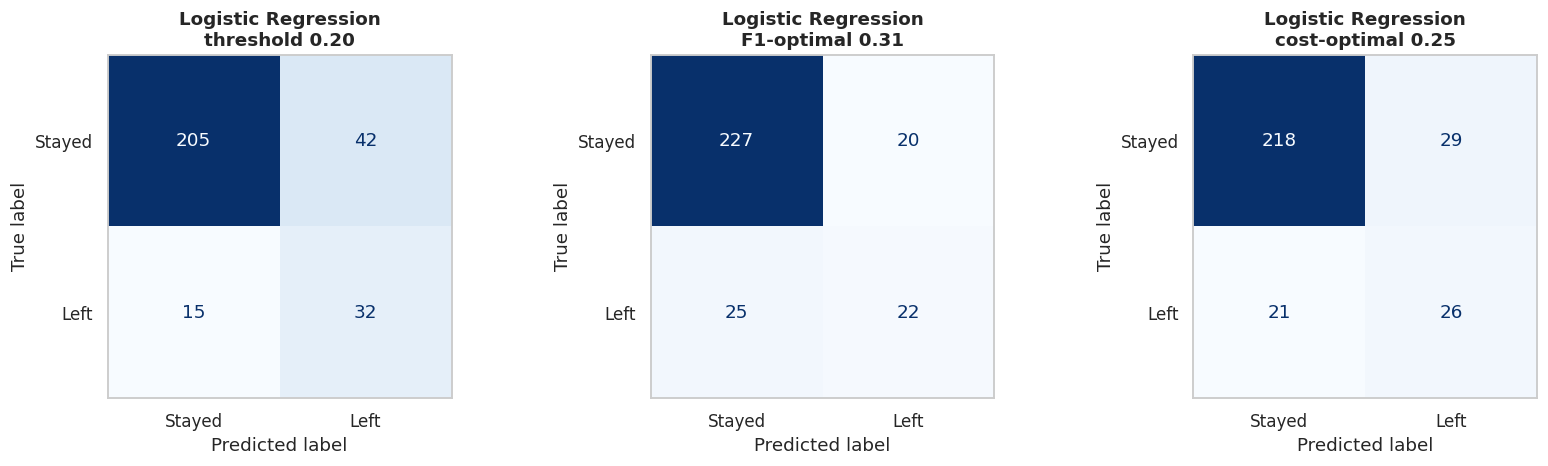

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (thr, tag) in zip(axes, [(0.2, "threshold 0.20"), (thr_f1, f"F1-optimal {thr_f1:.2f}"), (thr_cost, f"cost-optimal {thr_cost:.2f}")]):
    ConfusionMatrixDisplay.from_predictions(y_test, (p_final >= thr).astype(int), display_labels=["Stayed", "Left"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{best_name}\n{tag}"); ax.grid(False)
plt.tight_layout(); plt.show()

In [105]:
n_leavers = int(y_test.sum())
cost_none  = C_MISS * n_leavers                              # do nothing: every leaver is lost
cost_model = expected_cost(y_test, p_final, thr_cost)
cost_all   = expected_cost(y_test, np.ones(len(y_test)), 0.5) # flag everybody
print(f"Cost if HR does nothing                : {cost_none:6.2f} units")
print(f"Cost if HR approaches EVERY employee   : {cost_all:6.2f} units")
print(f"Cost with the model (threshold {thr_cost:.2f})  : {cost_model:6.2f} units")
print(f"==> saving vs doing nothing: {cost_none - cost_model:.2f} units ({(cost_none - cost_model)/cost_none:.0%}); "
      f"model flags {(p_final>=thr_cost).mean():.0%} of employees and reaches "
      f"{int(((p_final>=thr_cost)&(y_test.values==1)).sum())}/{n_leavers} leavers")

Cost if HR does nothing                :  94.00 units
Cost if HR approaches EVERY employee   :  95.20 units
Cost with the model (threshold 0.25)  :  83.90 units
==> saving vs doing nothing: 10.10 units (11%); model flags 19% of employees and reaches 26/47 leavers


**What this cell does.** **Cumulative gains chart** and risk bands: sort employees by predicted risk and see what share of all leavers is found in the top x% (this is the chart HR can act on).

**Expected result.** The red curve is well above the diagonal: contacting the **top 20% of employees by risk catches ≈ 45–60% of leavers** (lift ≈ 2.5–3×). The quintile table shows actual attrition rising from ≈ 2–5% (lowest quintile) to ≈ 35–50% (highest quintile).

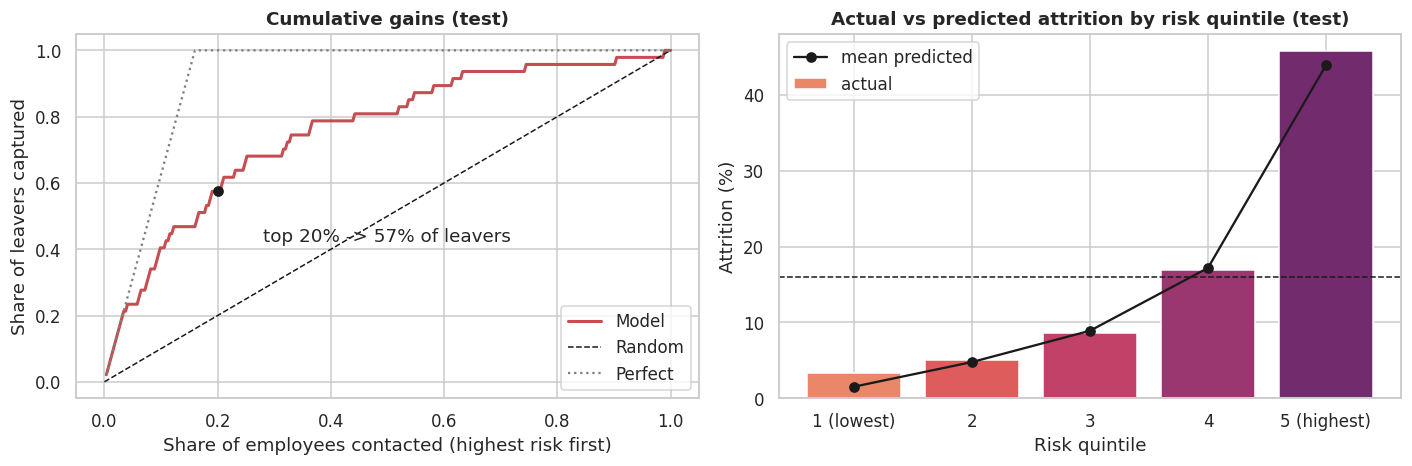

,employees,leavers,attrition_rate,avg_predicted,lift_vs_average,share_of_all_leavers
band,,,,,,
1 (lowest),59,2,3.4%,1.5%,0.21x,4.3%
2,59,3,5.1%,4.8%,0.32x,6.4%
3,58,5,8.6%,8.9%,0.54x,10.6%
4,59,10,16.9%,17.2%,1.06x,21.3%
5 (highest),59,27,45.8%,43.9%,2.86x,57.4%


In [106]:
order = np.argsort(-p_final)
y_sorted = y_test.values[order]
x_frac = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
gain = np.cumsum(y_sorted) / y_sorted.sum()
k20 = int(np.ceil(0.2 * len(y_sorted)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(x_frac, gain, color="#C44E52", lw=2, label="Model")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
perfect = np.minimum(x_frac / y_test.mean(), 1.0)
axes[0].plot(x_frac, perfect, color="gray", ls=":", label="Perfect")
axes[0].scatter([0.2], [gain[k20 - 1]], color="k", zorder=5)
axes[0].annotate(f"top 20% -> {gain[k20-1]:.0%} of leavers", (0.2, gain[k20 - 1]), xytext=(0.28, gain[k20 - 1] - 0.15))
axes[0].set(title="Cumulative gains (test)", xlabel="Share of employees contacted (highest risk first)", ylabel="Share of leavers captured"); axes[0].legend()

risk = pd.DataFrame({"proba": p_final, "left": y_test.values})
risk["band"] = pd.qcut(risk["proba"].rank(method="first"), 5, labels=["1 (lowest)", "2", "3", "4", "5 (highest)"])
bands = risk.groupby("band", observed=True).agg(employees=("left", "size"), leavers=("left", "sum"),
                                                 attrition_rate=("left", "mean"), avg_predicted=("proba", "mean"))
bands["lift_vs_average"] = bands["attrition_rate"] / y_test.mean()
bands["share_of_all_leavers"] = bands["leavers"] / bands["leavers"].sum()
axes[1].bar(bands.index.astype(str), bands["attrition_rate"] * 100, color=sns.color_palette("flare", 5), label="actual")
axes[1].plot(range(5), bands["avg_predicted"] * 100, "ko-", label="mean predicted")
axes[1].axhline(y_test.mean() * 100, color="k", ls="--", lw=1)
axes[1].set(title="Actual vs predicted attrition by risk quintile (test)", xlabel="Risk quintile", ylabel="Attrition (%)"); axes[1].legend()
plt.tight_layout(); plt.show()
bands.style.format({"attrition_rate": "{:.1%}", "avg_predicted": "{:.1%}", "lift_vs_average": "{:.2f}x", "share_of_all_leavers": "{:.1%}"})

## 9. How do all five models compare on the test set?

Section 7 *selected* the model on training data. This section shows all five on the held-out test set purely for **reporting** (the selection is not revisited).

**What this cell does.** Computes test probabilities for every tuned model, out-of-fold thresholds for each, bootstrap 95% confidence intervals of the test ROC-AUC, and a summary table.

**Expected result.** Test ROC-AUC between ≈ 0.70 and ≈ 0.85; the **95% intervals are ≈ ±0.07 wide and overlap for LR, XGBoost and Random Forest**: their order on this one split is not trustworthy. The Decision Tree is lowest. 'Train−Test gap' is large for the Random Forest (it memorises the training data).

In [107]:
proba_test  = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
proba_train = {n: m.predict_proba(X_train)[:, 1] for n, m in models.items()}

rng = np.random.default_rng(SEED)
def bootstrap_auc_ci(y_true, p, n_boot):
    y_arr = np.asarray(y_true); idx = np.arange(len(y_arr)); vals = []
    for _ in range(n_boot):
        s = rng.choice(idx, len(idx))
        if y_arr[s].min() == y_arr[s].max():
            continue
        vals.append(roc_auc_score(y_arr[s], p[s]))
    return np.percentile(vals, [2.5, 97.5])

summary = []
for n in MODEL_ORDER:
    lo, hi = bootstrap_auc_ci(y_test, proba_test[n], CFG["n_boot"])
    summary.append({"Model": n,
                    "CV ROC-AUC (selection)": cv_summary.loc[n, "ROC-AUC mean"],
                    "Test ROC-AUC": roc_auc_score(y_test, proba_test[n]),
                    "Test AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                    "Test PR-AUC": average_precision_score(y_test, proba_test[n]),
                    "Train ROC-AUC (refit)": roc_auc_score(y_train, proba_train[n])})
summary = pd.DataFrame(summary).set_index("Model")
summary["Train-Test gap"] = summary["Train ROC-AUC (refit)"] - summary["Test ROC-AUC"]
print(f"PR-AUC of a random classifier = prevalence = {y_test.mean():.3f}")
summary.style.format({c: "{:.3f}" for c in summary.columns if c != "Test AUC 95% CI"})

PR-AUC of a random classifier = prevalence = 0.160


,CV ROC-AUC (selection),Test ROC-AUC,Test AUC 95% CI,Test PR-AUC,Train ROC-AUC (refit),Train-Test gap
Model,,,,,,
Logistic Regression,0.829,0.807,"[0.729, 0.882]",0.576,0.872,0.065
Decision Tree,0.690,0.707,"[0.619, 0.788]",0.372,0.816,0.109
KNN,0.798,0.756,"[0.672, 0.828]",0.385,1.000,0.244
Random Forest,0.793,0.787,"[0.710, 0.854]",0.416,1.000,0.213
XGBoost,0.836,0.823,"[0.744, 0.892]",0.563,0.906,0.083


**What this cell does.** ROC curves, Precision-Recall curves and an overfitting chart (training-fold AUC vs CV AUC vs test AUC) for all five models.

**Expected result.** ROC/PR curves of LR and XGBoost are interwoven; the Decision Tree is clearly below. PR curves start high and fall (typical for ~16% prevalence); the dashed line is the random baseline at ≈ 0.16. In the right panel the Random Forest shows the largest gap between training (≈ 1.0) and CV/test (≈ 0.8): overfitting; Logistic Regression has almost none.

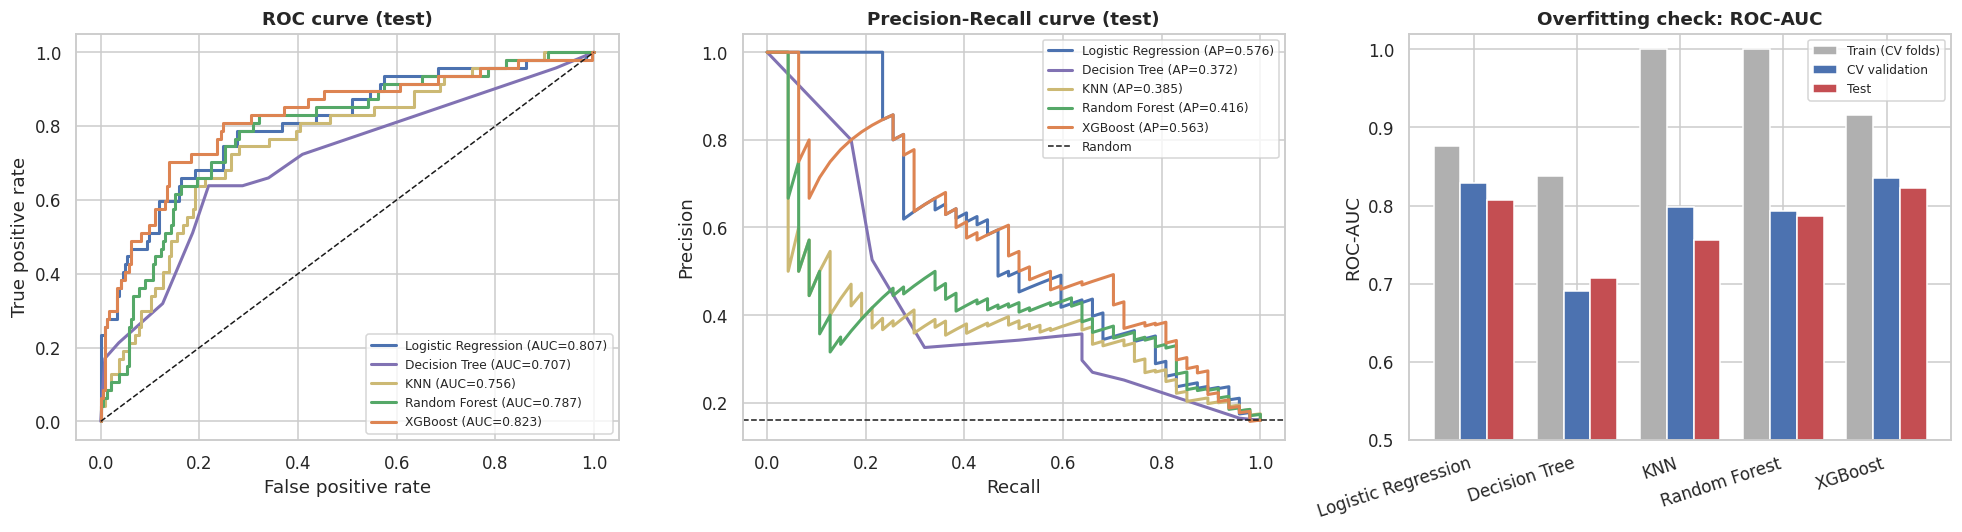

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for n, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, color=MODEL_COLORS[n], label=f"{n} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, lw=2, color=MODEL_COLORS[n], label=f"{n} (AP={average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Random")
axes[1].set(title="Precision-Recall curve (test)", xlabel="Recall", ylabel="Precision"); axes[1].legend(loc="upper right", fontsize=8)
x_ = np.arange(len(MODEL_ORDER)); w = .26
axes[2].bar(x_ - w, cv_summary["Train ROC-AUC (CV)"], w, label="Train (CV folds)", color="#B0B0B0")
axes[2].bar(x_, cv_summary["ROC-AUC mean"], w, label="CV validation", color="#4C72B0")
axes[2].bar(x_ + w, summary["Test ROC-AUC"], w, label="Test", color="#C44E52")
axes[2].set_xticks(x_); axes[2].set_xticklabels(MODEL_ORDER, rotation=18, ha="right")
axes[2].set_ylim(0.5, 1.02); axes[2].set(title="Overfitting check: ROC-AUC", ylabel="ROC-AUC"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Interpretation: what drives attrition?

### 10.1 The Decision Tree as readable rules

**What this cell does.** Draws the top 3 levels of the tuned Decision Tree and prints them as text rules.

**Expected result.** A small tree whose first splits use `OverTime`, `MonthlyIncome`/`TotalWorkingYears`/`Age`, `StockOptionLevel`. Orange nodes = majority 'Left', blue = majority 'Stayed'. Use it to *communicate* rules to HR, not to predict (its AUC is the lowest).

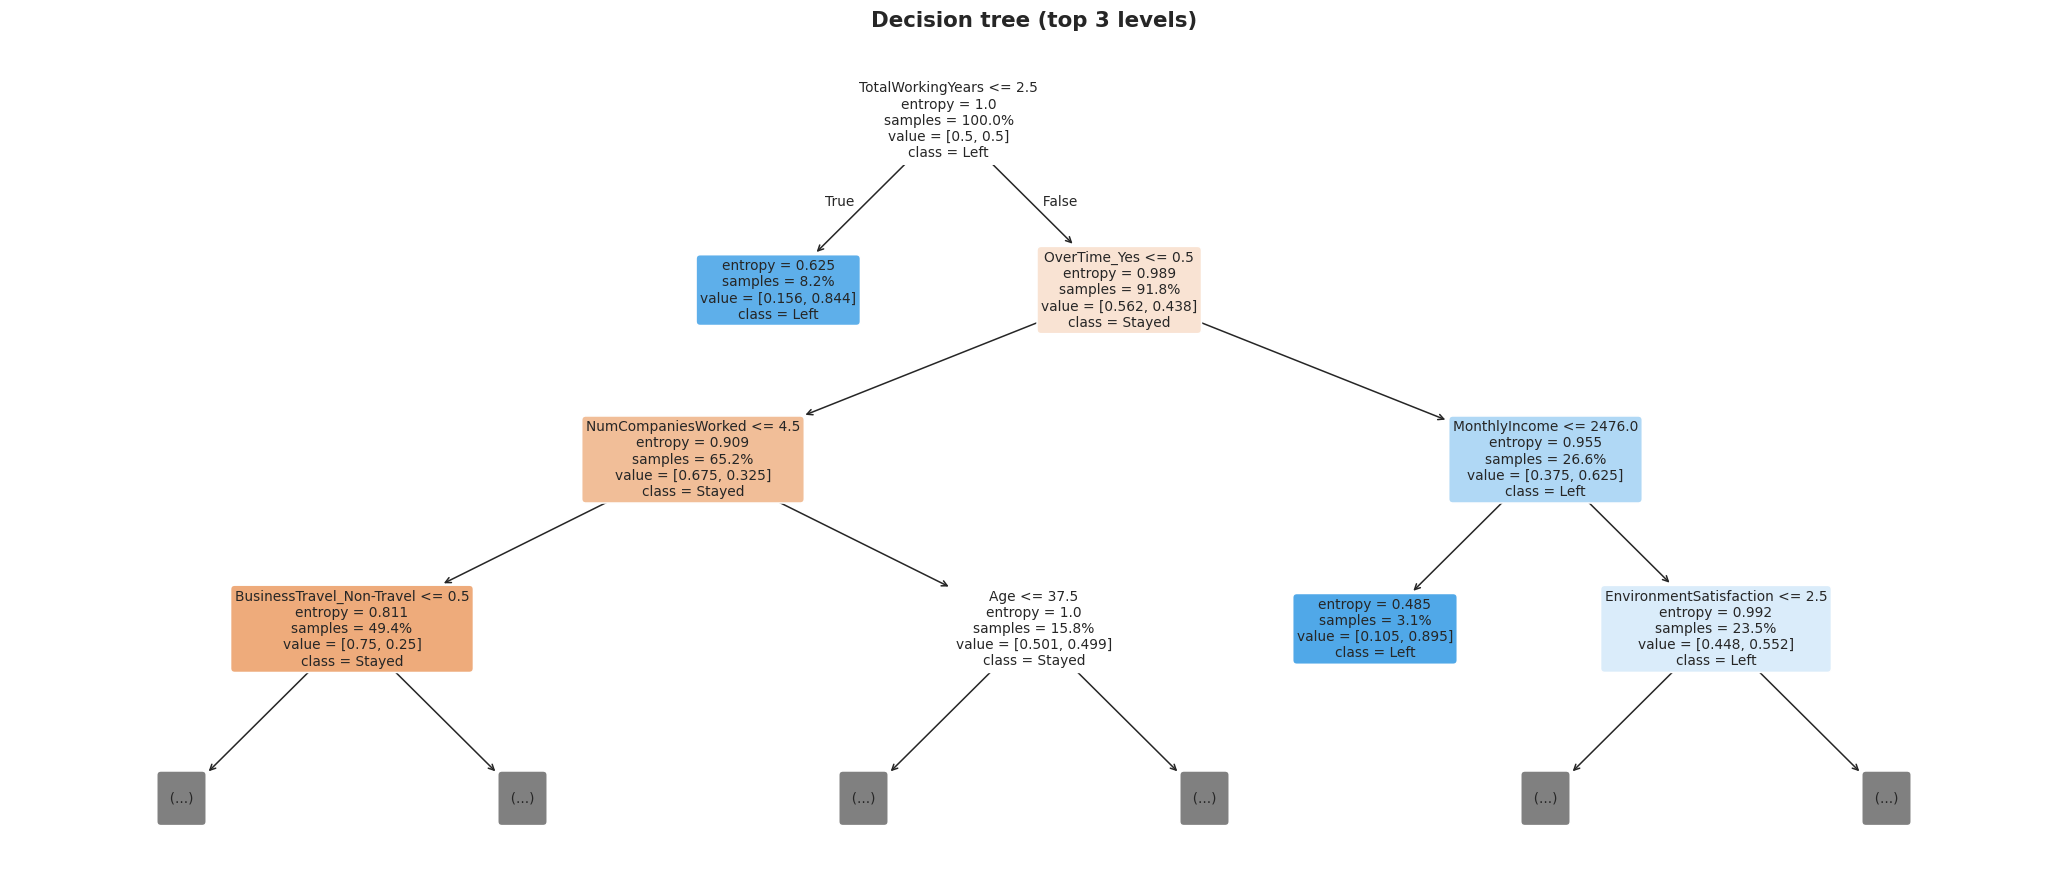

|--- TotalWorkingYears <= 2.50
|   |--- class: 1
|--- TotalWorkingYears >  2.50
|   |--- OverTime_Yes <= 0.50
|   |   |--- NumCompaniesWorked <= 4.50
|   |   |   |--- BusinessTravel_Non-Travel <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- BusinessTravel_Non-Travel >  0.50
|   |   |   |   |--- class: 0
|   |   |--- NumCompaniesWorked >  4.50
|   |   |   |--- Age <= 37.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Age >  37.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- OverTime_Yes >  0.50
|   |   |--- MonthlyIncome <= 2476.00
|   |   |   |--- class: 1
|   |   |--- MonthlyIncome >  2476.00
|   |   |   |--- EnvironmentSatisfaction <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- EnvironmentSatisfaction >  2.50
|   |   |   |   |--- truncated branch of depth 2



In [109]:
dt = models["Decision Tree"]
fig = plt.figure(figsize=(24, 10))
plot_tree(dt.named_steps["clf"], max_depth=3, feature_names=feat_names(dt), class_names=["Stayed", "Left"],
          filled=True, rounded=True, proportion=True, fontsize=9)
plt.title("Decision tree (top 3 levels)", fontsize=14, fontweight="bold"); plt.show()
print(export_text(dt.named_steps["clf"], feature_names=feat_names(dt), max_depth=3))

### 10.2 Logistic Regression coefficients

**What this cell does.** Shows the 12 largest coefficients of the Logistic Regression model as **odds multipliers**: numeric inputs are standardised (multiplier per +1 standard deviation), dummy variables are 0/1 (multiplier when the category applies). Red = raises risk, blue = lowers risk.

**Expected result.** Red: `OverTime_Yes`, `BusinessTravel_Travel_Frequently`, `MaritalStatus_Single`, `JobRole_Sales Representative`, `DistanceFromHome`, `NumCompaniesWorked`. Blue: `StockOptionLevel`, `JobSatisfaction`, `EnvironmentSatisfaction`, `JobInvolvement`, `WorkLifeBalance`, `TotalWorkingYears`/`YearsWithCurrManager`. Correlated seniority variables share weight, so read groups of features, not single ones.

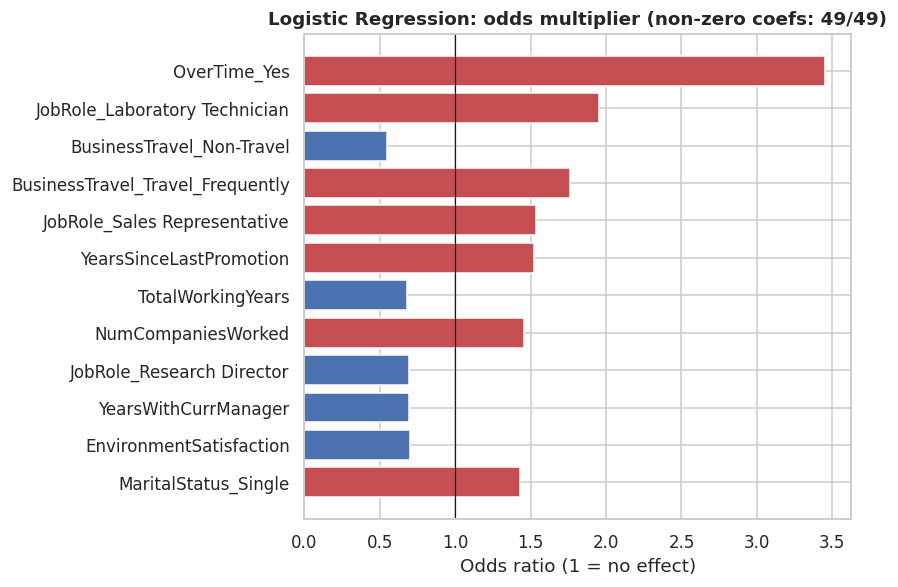

In [110]:
m = models["Logistic Regression"]
coef = pd.Series(m.named_steps["clf"].coef_[0], index=feat_names(m))
nz = coef[coef != 0]
top = nz.reindex(nz.abs().sort_values(ascending=False).index).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, np.exp(top.values), color=["#C44E52" if v > 0 else "#4C72B0" for v in top.values])
ax.axvline(1, color="k", lw=.8)
ax.set(title=f"Logistic Regression: odds multiplier (non-zero coefs: {(coef != 0).sum()}/{len(coef)})",
       xlabel="Odds ratio (1 = no effect)")
plt.tight_layout(); plt.show()

### 10.3 Built-in importance of the tree models

**What this cell does.** Impurity/gain importance of the Decision Tree, Random Forest and XGBoost (top 15 model columns each).

**Expected result.** `OverTime_Yes` / `MonthlyIncome` / `Age` / `TotalWorkingYears` / `StockOptionLevel` dominate. Warning: this kind of importance favours continuous and high-cardinality columns and splits credit among correlated features, so the next cell gives a more reliable view.

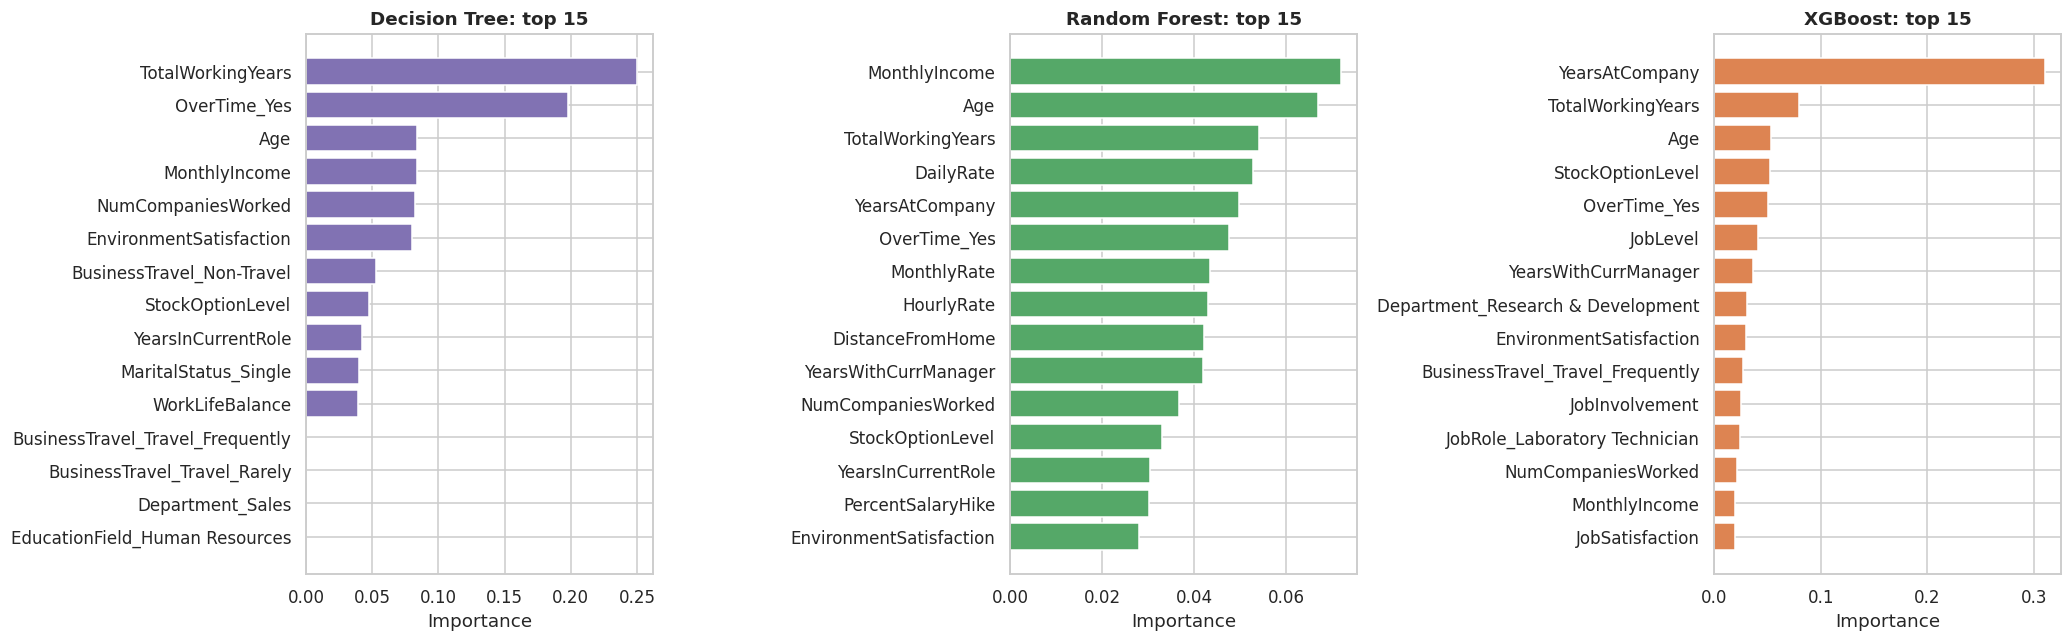

In [111]:
tree_models = [n for n in ["Decision Tree", "Random Forest", "XGBoost"]]
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, n in zip(axes, tree_models):
    m = models[n]
    imp = pd.Series(m.named_steps["clf"].feature_importances_, index=feat_names(m)).sort_values(ascending=False).head(15)[::-1]
    ax.barh(imp.index, imp.values, color=MODEL_COLORS[n]); ax.set_title(f"{n}: top 15"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

### 10.4 Permutation importance, grouped by original column

**What this cell does.** Shuffles **one original column at a time** (all its dummies and derived features move together because the whole pipeline is permuted) and measures the drop in test ROC-AUC. Grouping fixes the v2 problem where `JobRole` was split into 9 tiny dummy columns. Repeated many times; bars show ± 1 std.

**Expected result.** `OverTime` is #1 for almost all models (drop ≈ 0.03–0.06 AUC). Next: `MonthlyIncome`, `TotalWorkingYears`/`Age`/`JobLevel`, `StockOptionLevel`, `MaritalStatus`, `BusinessTravel`, `JobSatisfaction`/`EnvironmentSatisfaction`, `YearsWithCurrManager`. Many columns have importance ≈ 0 (or slightly negative = noise). Test-set permutation is noisy with 47 leavers: see 10.6 for the CV version.

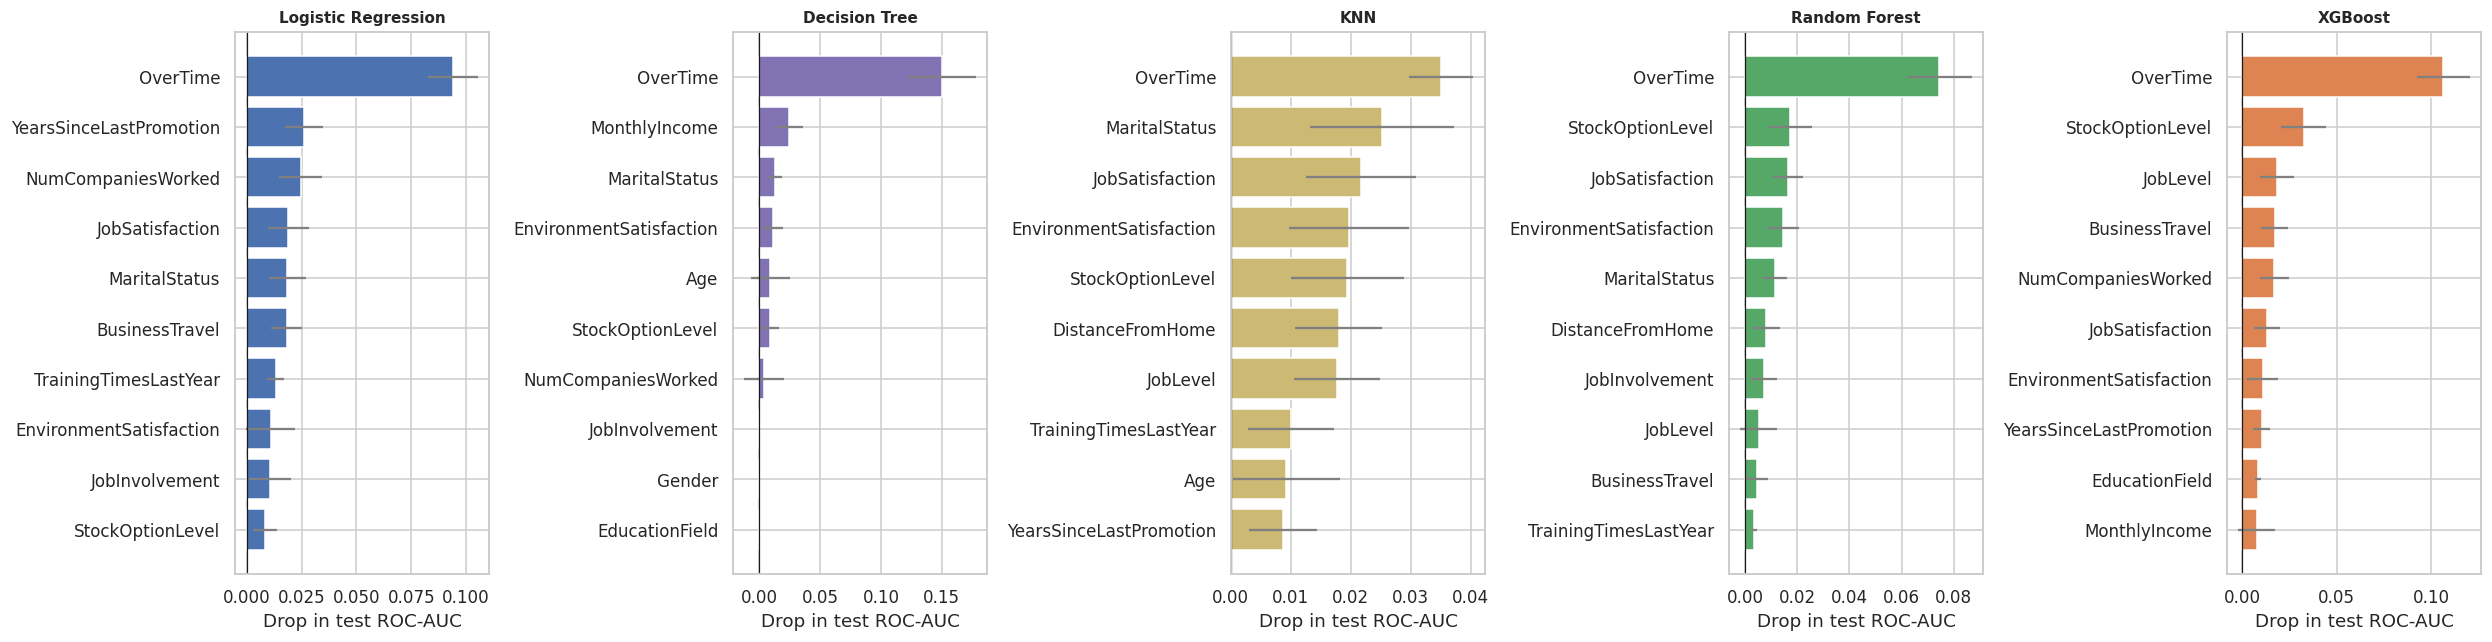

In [112]:
perm = {}
fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(4.6 * len(MODEL_ORDER), 6))
for ax, n in zip(axes, MODEL_ORDER):
    r = permutation_importance(models[n], X_test, y_test, scoring="roc_auc", n_repeats=CFG["perm_repeats"],
                               random_state=SEED, n_jobs=-1)
    perm[n] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X_test.columns)
    top = perm[n].sort_values("mean", ascending=False).head(10)[::-1]
    ax.barh(top.index, top["mean"], xerr=top["std"], color=MODEL_COLORS[n], ecolor="gray")
    ax.axvline(0, color="k", lw=.8); ax.set_title(n, fontsize=10); ax.set_xlabel("Drop in test ROC-AUC")
plt.tight_layout(); plt.show()

**What this cell does.** Rank agreement: the average importance rank of each original column across the five models.

**Expected result.** `OverTime` has average rank ≈ 1–2; a short list of 6–8 columns (income/seniority, stock options, marital status, travel, satisfaction) follow. Columns with a high average rank (≥ 15) are candidates to drop.

In [113]:
rank = pd.DataFrame({n: perm[n]["mean"].rank(ascending=False) for n in perm})
rank["avg_rank"] = rank.mean(axis=1)
rank.sort_values("avg_rank").head(12)

,Logistic Regression,Decision Tree,KNN,Random Forest,XGBoost,avg_rank
OverTime,1.000,1.000,1.000,1.000,1.000,1.000
StockOptionLevel,10.000,6.000,5.000,2.000,2.000,5.000
EnvironmentSatisfaction,8.000,4.000,4.000,4.000,7.000,5.400
JobSatisfaction,4.000,17.000,3.000,3.000,6.000,6.600
MaritalStatus,5.000,3.000,2.000,5.000,19.000,6.800
YearsSinceLastPromotion,2.000,17.000,10.000,12.000,8.000,9.800
MonthlyIncome,11.000,2.000,17.000,15.000,10.000,11.000
TrainingTimesLastYear,7.000,17.000,8.000,10.000,16.000,11.600
JobInvolvement,9.000,17.000,11.000,7.000,15.000,11.800
DistanceFromHome,17.000,17.000,6.000,6.000,14.000,12.000


**What this cell does.** **More reliable permutation importance for the selected model**: computed on the *validation part of each CV fold* (the model is re-fitted 5 times), so it uses all ≈ 190 training leavers instead of 47.

**Expected result.** Same top drivers as above but with **smaller error bars**; the ordering of the top 5–6 columns should be stable across both estimates. If a column is large in one estimate and ≈ 0 in the other, do not trust it.

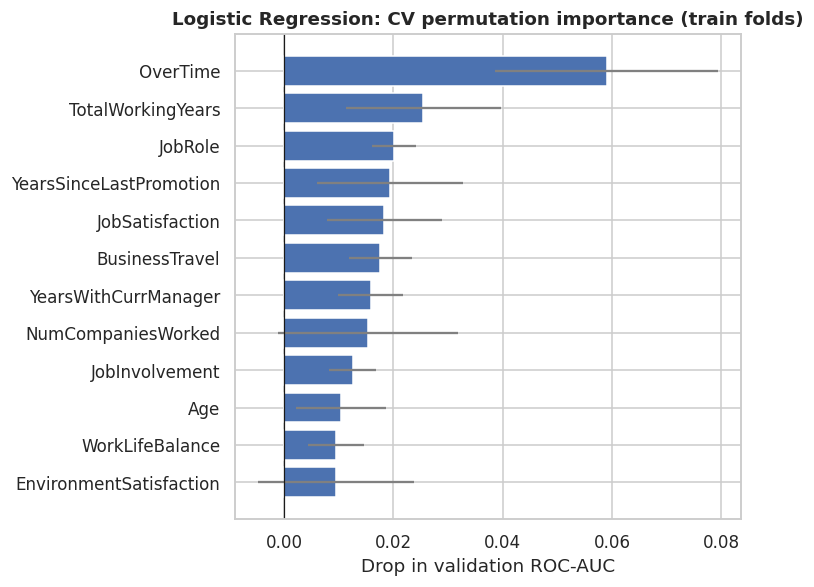

In [114]:
def cv_permutation_importance(model, X_, y_, cv, n_repeats):
    res = []
    for tr, va in cv.split(X_, y_):
        m = clone(model).fit(X_.iloc[tr], y_.iloc[tr])
        r = permutation_importance(m, X_.iloc[va], y_.iloc[va], scoring="roc_auc", n_repeats=n_repeats,
                                   random_state=SEED, n_jobs=-1)
        res.append(r.importances_mean)
    res = np.array(res)
    return pd.DataFrame({"mean": res.mean(0), "std": res.std(0)}, index=X_.columns)

cvperm = cv_permutation_importance(models[best_name], X_train, y_train, cv5, n_repeats=max(3, CFG["perm_repeats"] // 6))
top = cvperm.sort_values("mean", ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top["mean"], xerr=top["std"], color=MODEL_COLORS[best_name], ecolor="gray")
ax.axvline(0, color="k", lw=.8)
ax.set(title=f"{best_name}: CV permutation importance (train folds)", xlabel="Drop in validation ROC-AUC")
plt.tight_layout(); plt.show()

### 10.5 Partial dependence: *how* do the top drivers change the risk?

**What this cell does.** For the 6 most important columns (by test permutation importance of the selected model), sweeps the value of the column while keeping everyone else unchanged and plots the **average calibrated probability of leaving**. Numeric features use 25 quantile points; categorical features show one bar per category.

**Expected result.** `OverTime`: ≈ 3× higher risk with overtime. `MonthlyIncome`/`TotalWorkingYears`/`Age`: risk **falls steeply at low values and flattens** at higher ones (diminishing returns of pay/seniority). `StockOptionLevel`: biggest drop between level 0 and 1. Curves are averages over employees, not individual predictions.

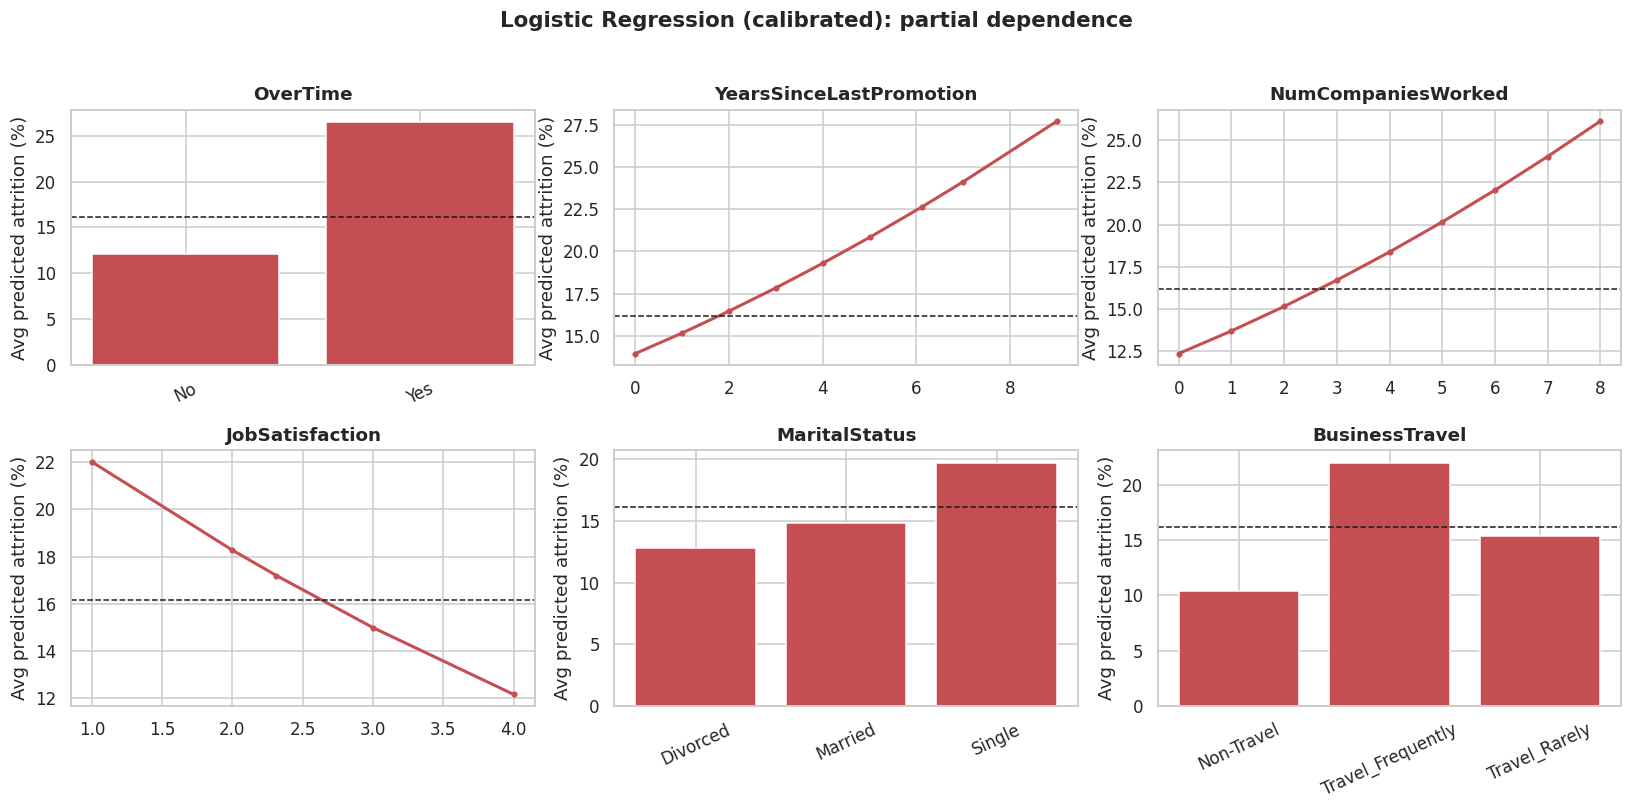

In [115]:
top_feats = perm[best_name]["mean"].sort_values(ascending=False).head(6).index.tolist()
Xp = X_train.copy()
num_present = [c for c in Xp.columns if pd.api.types.is_numeric_dtype(Xp[c])]
Xp[num_present] = Xp[num_present].astype(float)

fig, axes = grid_axes(len(top_feats), ncols=3, w=5, h=3.6)
for ax, f in zip(axes, top_feats):
    if f in num_present:
        vals = np.unique(np.quantile(Xp[f], np.linspace(0.05, 0.95, 25)))
        ys = []
        for v in vals:
            tmp = Xp.copy(); tmp[f] = v
            ys.append(final_model.predict_proba(tmp)[:, 1].mean() * 100)
        ax.plot(vals, ys, marker="o", ms=3, color="#C44E52", lw=2)
    else:
        cats = sorted(Xp[f].unique()); ys = []
        for v in cats:
            tmp = Xp.copy(); tmp[f] = v
            ys.append(final_model.predict_proba(tmp)[:, 1].mean() * 100)
        ax.bar([str(c) for c in cats], ys, color="#C44E52")
        ax.tick_params(axis="x", rotation=25)
    ax.axhline(y_train.mean() * 100, color="k", ls="--", lw=1)
    ax.set(title=f, ylabel="Avg predicted attrition (%)")
fig.suptitle(f"{best_name} (calibrated): partial dependence", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

## 11. Fairness and sensitive attributes

`Age`, `Gender` and `MaritalStatus` are legally and ethically sensitive. Using them in an HR model can create discrimination risk, even when they are predictive. Two checks:
1. **Ablation:** how much predictive power is lost if the model never sees them?
2. **Group report:** does the model flag some groups much more often than their true attrition rate would justify?

**What this cell does.** Re-evaluates the selected configuration **without** the sensitive columns using the same CV folds, and reports the paired AUC difference.

**Expected result.** The AUC change is small (typically **< 0.01–0.02**, within noise). If so, the recommendation is to **drop the sensitive attributes** from the production model: you lose almost nothing and remove a compliance risk. (`Age` information partly survives through tenure/experience variables.)

In [116]:
X_train_ns = X_train.drop(columns=SENSITIVE)
auc_ns = cross_validate(clone(models[best_name]), X_train_ns, y_train, cv=rcv, scoring="roc_auc", n_jobs=-1)["test_score"]
auc_with = cv_scores[best_name]["roc_auc"].values
d_ = auc_with - auc_ns
print(f"CV ROC-AUC with sensitive columns   : {auc_with.mean():.3f}")
print(f"CV ROC-AUC without {SENSITIVE}: {auc_ns.mean():.3f}")
print(f"Paired difference: {d_.mean():+.4f} +/- {d_.std():.4f}  -> "
      + ("negligible: safe to drop them." if abs(d_.mean()) < max(d_.std(), 0.01) else "noticeable: discuss with HR/legal before dropping."))

CV ROC-AUC with sensitive columns   : 0.829
CV ROC-AUC without ['Age', 'Gender', 'MaritalStatus']: 0.826
Paired difference: +0.0027 +/- 0.0072  -> negligible: safe to drop them.


**What this cell does.** Group report on the test set: for each Gender / MaritalStatus / AgeBand group, the real attrition rate, the share flagged by the model at the cost threshold, and recall / precision.

**Expected result.** Flag rates track real attrition rates (e.g. singles and under-30s are flagged more because they genuinely leave more). Watch for groups whose **flag rate is far above their real rate** or whose **recall is much lower** than others. Groups are small (a few dozen leavers), so differences of ± 10 points are noise.

In [117]:
T = X_test.copy()
T["y"] = y_test.values; T["flag"] = (p_final >= thr_cost)
T["AgeBand"] = pd.cut(T["Age"], [17, 29, 39, 70], labels=["<30", "30-39", "40+"])
rows = []
for g in ["Gender", "MaritalStatus", "AgeBand"]:
    for k, sub in T.groupby(g, observed=True):
        tp = int((sub.flag & (sub.y == 1)).sum())
        rows.append({"attribute": g, "group": str(k), "n": len(sub), "actual_attrition": sub.y.mean(),
                     "flagged_share": sub.flag.mean(),
                     "recall": tp / max(int(sub.y.sum()), 1), "precision": tp / max(int(sub.flag.sum()), 1)})
pd.DataFrame(rows).set_index(["attribute", "group"]).style.format(
    {"actual_attrition": "{:.1%}", "flagged_share": "{:.1%}", "recall": "{:.2f}", "precision": "{:.2f}"})

## 12. Saving and using the model

**What this cell does.** Saves the calibrated pipeline **plus** its metadata (thresholds, expected input columns, library version, date, cost assumptions) in one file, reloads it, and verifies that the reloaded model reproduces the same probabilities.

**Expected result.** Prints `Reloaded model reproduces the in-memory predictions: True`. **To use the file in another session you must first run the cell that defines `select_cat` and `select_num` (Section 4) so the pickle can find them,** and use the same major scikit-learn version.

In [118]:
artifact = {
    "model": final_model, "model_name": best_name,
    "threshold_cost": thr_cost, "threshold_f1": thr_f1,
    "raw_columns": list(X.columns), "sklearn_version": sklearn.__version__, "trained_on": str(date.today()),
    "cost_assumptions": {"C_MISS": C_MISS, "C_INT": C_INT, "SUCCESS": SUCCESS},
}
joblib.dump(artifact, "attrition_model.joblib")
loaded = joblib.load("attrition_model.joblib")

def score_employees(df_raw, art=loaded):
    """Takes RAW employee records (same columns as the IBM file, without Attrition) and returns risk scores."""
    p = art["model"].predict_proba(df_raw[art["raw_columns"]])[:, 1]
    thr = art["threshold_cost"]
    out = pd.DataFrame({"attrition_probability": p}, index=df_raw.index)
    out["risk_band"] = pd.cut(p, [-0.01, thr / 2, thr, 1.01], labels=["Low", "Medium", "High"])
    out["recommend_action"] = p >= thr
    return out

check = score_employees(X_test)["attrition_probability"].values
print("Reloaded model reproduces the in-memory predictions:", bool(np.allclose(check, p_final)))
demo = score_employees(X_test.head(8)).assign(actual_left=y_test.head(8).values)
demo

Reloaded model reproduces the in-memory predictions: True


,attrition_probability,risk_band,recommend_action,actual_left
1061,0.122,Low,False,0
891,0.011,Low,False,0
456,0.176,Medium,False,0
922,0.009,Low,False,0
69,0.271,High,True,1
1164,0.225,Medium,False,0
406,0.025,Low,False,0
1330,0.032,Low,False,0


## 13. Conclusions (generated from this run)

**What this cell does.** Prints the key results of **this** run in plain sentences: selected model, honest performance range, business value, and the top drivers (from the CV permutation importance).

**Expected result.** A short report. On the real IBM data expect: selected model = Logistic Regression; CV ROC-AUC ≈ 0.84; test ROC-AUC ≈ 0.80 with a ≈ ±0.07 interval; top-20% of employees by risk contain ≈ half of the leavers; top drivers led by `OverTime`.

In [119]:
lo_hi = summary.loc[best_name, "Test AUC 95% CI"]
drivers = cvperm["mean"].sort_values(ascending=False).head(5)
print("=" * 78)
print(f"Selected model (parsimony rule on repeated CV): {best_name}")
print(f"  CV ROC-AUC {cv_summary.loc[best_name, 'ROC-AUC mean']:.3f} +/- {cv_summary.loc[best_name, 'ROC-AUC std']:.3f}"
      f" | test ROC-AUC {summary.loc[best_name, 'Test ROC-AUC']:.3f}, 95% CI {lo_hi}")
print(f"  Calibrated Brier score {cal.iloc[1]['Brier']:.3f} (base-rate model: {base_brier:.3f})")
print(f"Models tied with the best within {TIE_TOL} AUC: {eligible}")
print(f"Contacting the top 20% by predicted risk captures {gain[k20-1]:.0%} of leavers on the test set.")
print(f"At the cost-optimal threshold ({thr_cost:.2f}) the expected cost falls by {(cost_none-cost_model)/cost_none:.0%} vs doing nothing")
print("Top drivers (CV permutation importance): " + ", ".join(f"{k} ({v:.3f})" for k, v in drivers.items()))
print("=" * 78)

Selected model (parsimony rule on repeated CV): Logistic Regression
  CV ROC-AUC 0.829 +/- 0.039 | test ROC-AUC 0.807, 95% CI [0.729, 0.882]
  Calibrated Brier score 0.100 (base-rate model: 0.134)
Models tied with the best within 0.01 AUC: ['Logistic Regression', 'XGBoost']
Contacting the top 20% by predicted risk captures 57% of leavers on the test set.
At the cost-optimal threshold (0.25) the expected cost falls by 11% vs doing nothing
Top drivers (CV permutation importance): OverTime (0.059), TotalWorkingYears (0.026), JobRole (0.020), YearsSinceLastPromotion (0.019), JobSatisfaction (0.018)
